# SciRecQA Benchmark Construction — Notebook 01+02
### *Verified Scientific Recommendation with Hallucination-Labeled Rationales*

**Benchmark**: SciRecQA v1.1  
**Purpose**: End-to-end construction of the SciRecQA benchmark for the MAPER
(Multi-Agent Personalized and Evidence-verified Recommender) paper.

---

**What this notebook produces**

| Output file | Description |
|---|---|
| `data/scireqa/scireqa_arxiv.jsonl` | 6 000 instances, arXiv CS, train/val/test |
| `data/scireqa/scireqa_acl.jsonl` | 2 000 instances, ACL Anthology, train/val/test |
| `data/scireqa/scireqa_pubmed.jsonl` | 2 000 instances, PubMed, **test-only** (zero-shot) |
| `data/scireqa/scireqa_full.jsonl` | Combined 10 000 instances |
| `data/cleaned_metadata.csv` | Deduped papers metadata |
| `data/rated_papers_split.csv` | User-stratified train/val/test split |
| `reports/eda_*.png` | EDA figures |
| `reports/benchmark_stats.json` | Statistics for paper Table 3 |

**Instance schema**: `SciRecQA v1.0` (see Section 2)  
**Hallucination labels**: automatically generated via `cross-encoder/nli-deberta-v3-small`,
`human_verified=False`. Human annotation of a stratified 500-instance subset
is performed in **Notebook 05** (after benchmark run completes).

**Query types**

| Type | Description | Domains |
|---|---|---|
| `history_based` | Realistic "I read X, find more" query (≤200 chars) | arXiv CS |
| `natural_language` | Explicit concept/keyword query | ACL Anthology, PubMed |
| `hybrid` | User-typed query personalised with profile keywords | arXiv CS |

> **Note on hallucination labels**: Labels are `auto_nli` (automatically generated
> by an NLI model, `human_verified=False`). The paper reports both automatic and human
> agreement numbers. Do not confuse `auto_nli` labels with the final human-verified
> gold labels — those come from Notebook 05.

In [1]:
# == Wipe ALL previous Kaggle output (start fresh) ============================
# Removes everything under /kaggle/working: rationale checkpoints, saved JSONL
# benchmark files, stats, etc. /kaggle/input is read-only and is NOT touched.
import shutil
from pathlib import Path

WORKING = Path("/kaggle/working")

removed = []
for item in WORKING.iterdir():
    # keep nothing — clear checkpoints, benchmark files, caches, the lot
    try:
        if item.is_dir() and not item.is_symlink():
            shutil.rmtree(item, ignore_errors=True)
        else:
            item.unlink(missing_ok=True)
        removed.append(item.name)
    except Exception as e:
        print(f"  could not remove {item.name}: {e}")

print(f"Cleared /kaggle/working — removed {len(removed)} item(s):")
for name in sorted(removed):
    print("  -", name)
print("Remaining:", [p.name for p in WORKING.iterdir()] or "(empty)")


Cleared /kaggle/working — removed 1 item(s):
  - .virtual_documents
Remaining: (empty)


In [2]:
# ── Dependencies ─────────────────────────────────────────────────────────────
# Core
import json, re, time, random, hashlib, os, warnings
from pathlib import Path
from typing import Dict, List, Optional, Tuple
from collections import Counter, defaultdict
from datetime import date

# Data
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm

# ML
import torch
from sklearn.decomposition import PCA
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity

# API
import requests

# v1.1: MiniCheck grounding fact-checker -- installed from GitHub (it is NOT on PyPI).
# Requires notebook Internet = ON. If it fails, the pipeline falls back to the NLI model.
import importlib, importlib.util as _ilu
if _ilu.find_spec("minicheck") is None:
    import subprocess as _sp, sys as _sys
    _sp.run([_sys.executable, "-m", "pip", "install", "-q",
             "minicheck @ git+https://github.com/Liyan06/MiniCheck.git@main"], check=False)
    importlib.invalidate_caches()
print("MiniCheck available:", _ilu.find_spec("minicheck") is not None,
      "(if False: turn on notebook Internet; labeling will fall back to the NLI model)")

warnings.filterwarnings("ignore")
random.seed(42)
np.random.seed(42)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120

print("PyTorch version :", torch.__version__)
print("CUDA available  :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU             :", torch.cuda.get_device_name(0))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 53.9 MB/s eta 0:00:00


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cudf-cu12 26.2.1 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cudf-cu12 26.2.1 requires numba-cuda[cu12]<0.23.0,>=0.22.2, but you hav

MiniCheck available: True (if False: turn on notebook Internet; labeling will fall back to the NLI model)
PyTorch version : 2.10.0+cu128
CUDA available  : True
GPU             : Tesla T4


## 1. Configuration

In [ ]:
# == Configuration - change ONLY here =========================================
# Benchmark
BENCHMARK_VERSION   = "1.1"               # v1.1: leakage-free arXiv GT + enriched fields
CONSTRUCTION_DATE   = str(date.today())
TARGET_ARXIV        = 6_000          # target arXiv CS instances
TARGET_ACL          = 2_000          # target ACL Anthology instances
TARGET_PUBMED       = 2_000          # target PubMed instances (test-only)
MIN_GT_PAPERS       = 3              # minimum ground-truth papers per instance
MAX_GT_PAPERS       = 10             # maximum ground-truth papers per instance
GT_SAMPLE_MIN       = 3              # v1.1: GT set size is sampled in [MIN, MAX] for variance
GT_SAMPLE_MAX       = 8
PROFILE_MIN_PAPERS  = 3              # v1.1: min history papers kept VISIBLE in profile
N_HARD_NEGATIVES    = 5              # v1.1: hard negatives per instance
QUERY_MAX_LEN       = 200            # max chars for any query string
MIN_CLAIM_LEN       = 20             # min chars to keep a claim sentence

# Grounding-label backend (v1.1): MiniCheck = claim-grounded-in-document checker
LABELER             = "minicheck"   # "minicheck" (recommended) | "nli"
MINICHECK_MODEL     = "flan-t5-large"   # 'roberta-large' | 'deberta-v3-large' | 'flan-t5-large'
MINICHECK_SUPPORT_THRESHOLD   = 0.50    # support prob >= this -> "supported"
MINICHECK_UNSUPPORT_THRESHOLD = 0.20    # support prob <  this -> "unsupported"; between -> "neutral"
#   ^ CALIBRATE these on the human gold subset in agentic-nb2, then update + re-run.
# Generic-NLI fallback (used only if MiniCheck is unavailable) - upgraded from the
# tiny v1.0 model to a strong DeBERTa-v3-large trained on MNLI+FEVER+ANLI.
NLI_MODEL_NAME      = "MoritzLaurer/DeBERTa-v3-large-mnli-fever-anli-ling-wanli"
NLI_BATCH_SIZE      = 16             # lower to 8 if OOM on P100

# Rationale generation -- v1.1: open-weights flagship via OpenRouter
RATIONALE_MODEL       = "meta-llama/llama-3.3-70b-instruct"
RATIONALE_MAX_TOKENS  = 300
RATIONALE_TEMPERATURE = 0.4         # keep some variation -> realistic grounded/ungrounded spread
OPENROUTER_BASE_URL   = "https://openrouter.ai/api/v1"
# Reproducibility: pin ALL rationales to ONE host so quantization / serving stays
# constant across the whole benchmark (OpenRouter load-balances by default).
OPENROUTER_PROVIDER        = "Novita"      # single host: ONLY provider serving llama-3.3-70b at bf16 *and* honoring seed (verified via OpenRouter /endpoints). DeepInfra=fp8 only -> bf16 pin matched no route -> all calls failed.
OPENROUTER_ALLOW_FALLBACKS = False          # fail+retry rather than silently switch host
OPENROUTER_QUANT           = "bf16"         # pin precision (None to disable); bf16/fp16 best for gold
RATIONALE_SEED             = 42             # determinism hint (honored where provider supports it)
SAVE_EVERY            = 200          # checkpoint frequency
GEN_CONCURRENCY       = 8            # parallel rationale requests (I/O-bound; same cost/quality)

# Splits (arXiv + ACL only - PubMed is always test-only)
TRAIN_FRAC, VAL_FRAC, TEST_FRAC = 0.70, 0.15, 0.15

# Paths
IS_KAGGLE = os.path.exists("/kaggle/input")
if IS_KAGGLE:
    DATA_DIR   = Path("/kaggle/input/datasets/joytuntonny/recommendation-system")
    EMB_DIR    = Path("/kaggle/input/datasets/reapers2025/acl-embeddings")
    OUTPUT_DIR = Path("/kaggle/working")
else:
    DATA_DIR   = Path("../data")
    EMB_DIR    = Path("../embeddings")
    OUTPUT_DIR = Path("../data")

SCIREQA_DIR  = OUTPUT_DIR / "scireqa"
REPORTS_DIR  = OUTPUT_DIR / "reports"
SCIREQA_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# API keys
def _get_secret(name):
    if IS_KAGGLE:
        try:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret(name)
        except Exception:
            pass
    return os.getenv(name, "")

S2_API_KEY        = _get_secret("SEMANTIC_SCHOLAR_API_KEY")
OPENAI_API_KEY    = _get_secret("OPENAI_API_KEY")       # legacy / optional
OPENROUTER_API_KEY = _get_secret("OPENROUTER_API_KEY")  # v1.1 rationale backend

S2_BASE  = "https://api.semanticscholar.org/graph/v1"
S2_HDRS  = {"x-api-key": S2_API_KEY} if S2_API_KEY else {}

print("Running on Kaggle    :", IS_KAGGLE)
print("Data dir             :", DATA_DIR)
print("Output dir           :", OUTPUT_DIR)
print("S2 API key loaded    :", bool(S2_API_KEY))
print("OpenRouter key loaded:", bool(OPENROUTER_API_KEY))
print(f"Rationale model      : {RATIONALE_MODEL}")
print(f"Benchmark version    : {BENCHMARK_VERSION}  ({CONSTRUCTION_DATE})")


Running on Kaggle    : True
Data dir             : /kaggle/input/datasets/joytuntonny/recommendation-system
Output dir           : /kaggle/working
S2 API key loaded    : True
OpenRouter key loaded: True
Rationale model      : meta-llama/llama-3.3-70b-instruct
Benchmark version    : 1.1  (2026-06-08)


## 2. SciRecQA Schema v1.1

Each instance in `scireqa_full_v1.1.jsonl` conforms to the schema below.
This cell is **documentation only** — it defines the contract for all
downstream notebooks (embeddings, training, evaluation, human annotation).

```json
{
  "id":                 "<12-char MD5 hex — unique across all three corpora>",
  "benchmark_version":  "1.1",
  "construction_date":  "YYYY-MM-DD",
  "domain":             "arxiv_cs | acl_anthology | pubmed",
  "split":              "train | val | test",
  "annotation_status":  "auto_labeled | pending_human | human_verified",

  "user_id":            "<string>",
  "user_profile": {
    "papers":    ["paper_id_1", "..."],
    "titles":    ["title_1",    "..."],
    "abstracts": ["abstract_1", "..."],
    "domain_cluster": "<optional — pubmed only>"
  },

  "query":          "<ecologically valid user query, max 200 chars>",
  "query_type":     "history_based | natural_language | hybrid",
  "original_query": "<raw source string before query formatting>",
  "query_paper_id": "<paper_id of the query-anchor paper>",

  "ground_truth_papers": [
    {
      "paper_id": "...", "title": "...", "abstract": "...",
      "year": 2023, "venue": "...", "authors": ["..."]
    }
  ],

  "hard_negatives": [
    { "paper_id": "...", "title": "...", "score": 0.88,
      "source": "embedding_knn (arxiv) | same_venue (acl/pubmed)" }
  ],
  "difficulty_score": 0.18,
  "query_quality": { "length": 0.6, "specificity": 0.5, "type_fit": 1.0, "overall": 0.7 },

  "reference_rationale": "<Llama-3.3-70B generated, grounded in abstracts>",
  "rationale_metadata": {
    "model":            "meta-llama/llama-3.3-70b-instruct",
    "served_by":        "<pinned OpenRouter host, e.g. DeepInfra>",
    "generated":        true,
    "generation_date":  "YYYY-MM-DD"
  },

  "hallucination_labels": [
    {
      "claim_id":       "000",
      "claim_text":     "<atomic claim sentence>",
      "claim_type":     "factual_candidate | general_statement",
      "verdict":        "supported | unsupported | neutral | general_statement | pending_annotation",
      "confidence":     0.9412,
      "label_type":     "auto_nli | rule_general | pending",
      "model":          "cross-encoder/nli-deberta-v3-small",
      "human_verified": false,
      "human_label":    null
    }
  ],

  "entity_verification": {
    "total_cited":          3,
    "verified":             3,
    "unverified":           [],
    "citation_trust_score": 1.0
  }
}
```

> **v1.1 note** — `auto_nli` verdicts are *silver* labels (small NLI model);
> the human-verified subset (see `agentic-nb2-human-annotation.ipynb`) is the *gold*
> standard. Only `factual_candidate` claims are sent to NLI; `general_statement`
> claims are labelled by rule. New v1.1 fields: `hard_negatives`, `difficulty_score`,
> `query_quality`, and per-claim `claim_type`.

**Annotation lifecycle**

```
agentic-nb1  →  auto_labeled   (hallucination_labels filled, human_verified=False)
agentic-nb2  →  human_verified (500-instance stratified sample; IAA computed)
Paper Table  →  reports both auto_nli (silver) agreement and human IAA (Cohen κ, Krippendorff α)
```

## 3. Load All Datasets

In [4]:
# ── Load all CSVs ─────────────────────────────────────────────────────────────
papers_df   = pd.read_csv(DATA_DIR / "papers_metadata.csv")
rated_df    = pd.read_csv(DATA_DIR / "rated_papers.csv")
implicit_df = pd.read_csv(DATA_DIR / "implicit_interactions.csv")
abstract_df = pd.read_csv(DATA_DIR / "abstract_sentences.csv")

print(f"papers_metadata : {papers_df.shape}")
print(f"rated_papers    : {rated_df.shape}")
print(f"implicit        : {implicit_df.shape}")
print(f"abstract_sents  : {abstract_df.shape}")

# ── Load JSON metadata ────────────────────────────────────────────────────────
meta_json_path = Path("/kaggle/input/datasets/reapers2025/paper-metadata/paper_metadata.json") \
    if IS_KAGGLE else DATA_DIR / "paper_metadata.json"

with open(meta_json_path, "r", encoding="utf-8") as f:
    paper_meta_json = json.load(f)

print(f"\npaper_metadata.json entries: {len(paper_meta_json)}")
if isinstance(paper_meta_json, list):
    print("Format: list | Keys:", list(paper_meta_json[0].keys()) if paper_meta_json else [])
else:
    first_key = list(paper_meta_json.keys())[0]
    print(f"Format: dict | Sample key '{first_key}' sub-keys:", list(paper_meta_json[first_key].keys()))

# ── Load embeddings ───────────────────────────────────────────────────────────
emb_256d = np.load(EMB_DIR / "paper_embeddings_256d.npy")
emb_full = np.load(EMB_DIR / "paper_embeddings_full.npy")

with open(EMB_DIR / "paper_id_mapping.json") as f:
    paper_id_mapping = json.load(f)

print(f"\nEmbeddings 256d : {emb_256d.shape}")
print(f"Embeddings full : {emb_full.shape}")
print(f"ID mapping size : {len(paper_id_mapping)}")

papers_metadata : (239618, 7)
rated_papers    : (774092, 4)
implicit        : (556324, 3)
abstract_sents  : (2538, 5)

paper_metadata.json entries: 239618
Format: list | Keys: ['arxiv_id', 'title', 'abstract', 'authors']

Embeddings 256d : (239618, 256)
Embeddings full : (239618, 1024)
ID mapping size : 239618


## 4. Papers Metadata — EDA

arxiv_id      object
title         object
abstract      object
authors       object
published     object
categories    object
pdf_url       object
dtype: object


,arxiv_id,title,abstract,authors,published,categories,pdf_url
0,2004.12652,Self-supervised Keypoint Correspondences for M...,Video annotation is expensive and time consumi...,"['Umer Rafi', 'Andreas Doering', 'Bastian Leib...",NaN,NaN,NaN
1,2404.06218,Quantum Circuit $C^*$-algebra Net,This paper introduces quantum circuit $C^*$-al...,"['Yuka Hashimoto', 'Ryuichiro Hataya']",NaN,NaN,NaN
2,2405.04180,Sora Detector: A Unified Hallucination Detecti...,The rapid advancement in text-to-video (T2V) g...,"['Zhixuan Chu', 'Lei Zhang', 'Yichen Sun', 'Si...",NaN,NaN,NaN


,missing,pct
title,3524,1.47
abstract,3524,1.47
published,230801,96.32
categories,230801,96.32
pdf_url,230801,96.32


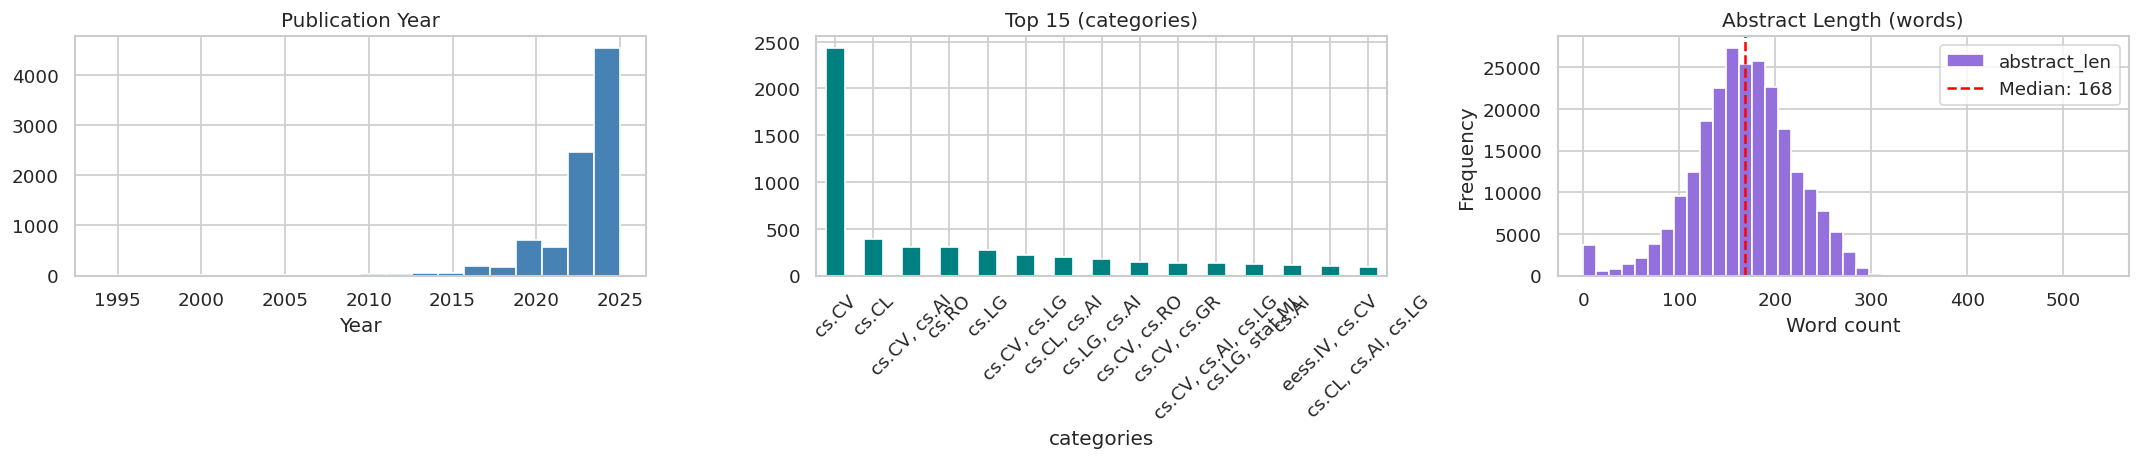

In [5]:
print(papers_df.dtypes)
display(papers_df.head(3))

# ── Missing value audit ────────────────────────────────────────────────────────
missing     = papers_df.isnull().sum()
missing_pct = (missing / len(papers_df) * 100).round(2)
display(pd.DataFrame({"missing": missing, "pct": missing_pct}).query("missing > 0"))

# ── Distribution plots ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

year_col = next((c for c in ["year", "published"] if c in papers_df.columns), None)
if year_col:
    years = (pd.to_datetime(papers_df[year_col], errors="coerce").dt.year
             if year_col == "published" else papers_df[year_col].dropna().astype(int))
    years.dropna().astype(int).hist(bins=20, ax=axes[0], color="steelblue", edgecolor="white")
    axes[0].set_title("Publication Year"); axes[0].set_xlabel("Year")
else:
    axes[0].text(0.5, 0.5, "No year column", ha="center"); axes[0].set_title("Year")

venue_col = next((c for c in ["venue","source","journal","conference","categories"]
                  if c in papers_df.columns), None)
if venue_col:
    papers_df[venue_col].value_counts().head(15).plot(kind="bar", ax=axes[1], color="teal")
    axes[1].set_title(f"Top 15 ({venue_col})"); axes[1].tick_params(axis="x", rotation=45)

if "abstract" in papers_df.columns:
    papers_df["abstract_len"] = papers_df["abstract"].fillna("").str.split().str.len()
    papers_df["abstract_len"].plot(kind="hist", bins=40, ax=axes[2],
                                    color="mediumpurple", edgecolor="white")
    axes[2].set_title("Abstract Length (words)"); axes[2].set_xlabel("Word count")
    med = papers_df["abstract_len"].median()
    axes[2].axvline(med, color="red", linestyle="--", label=f"Median: {med:.0f}")
    axes[2].legend()

plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig_eda_papers.png")
plt.show()

## 5. Interaction Data — EDA

Rated papers sample:
     arxiv_id  user_id  rating                 time
0  2004.12909     7318      -1  2022-11-20 21:34:43
1  2004.12909     8775      -1  2022-11-20 17:30:48
2  2004.12909    14542      -1  2022-11-17 17:53:51

Implicit interactions sample:
     arxiv_id  user_id                        time
0  2502.07685    12951  2025-02-17 12:33:55.499334
1  2004.13166     8569                         NaN
2  2004.12989    10678         2022-11-03 06:42:00

Total users: 13352 | Avg ratings/user: 58.0
count    774092.000000
mean          0.168941
std           0.985627
min          -1.000000
25%          -1.000000
50%           1.000000
75%           1.000000
max           1.000000
Name: rating, dtype: float64


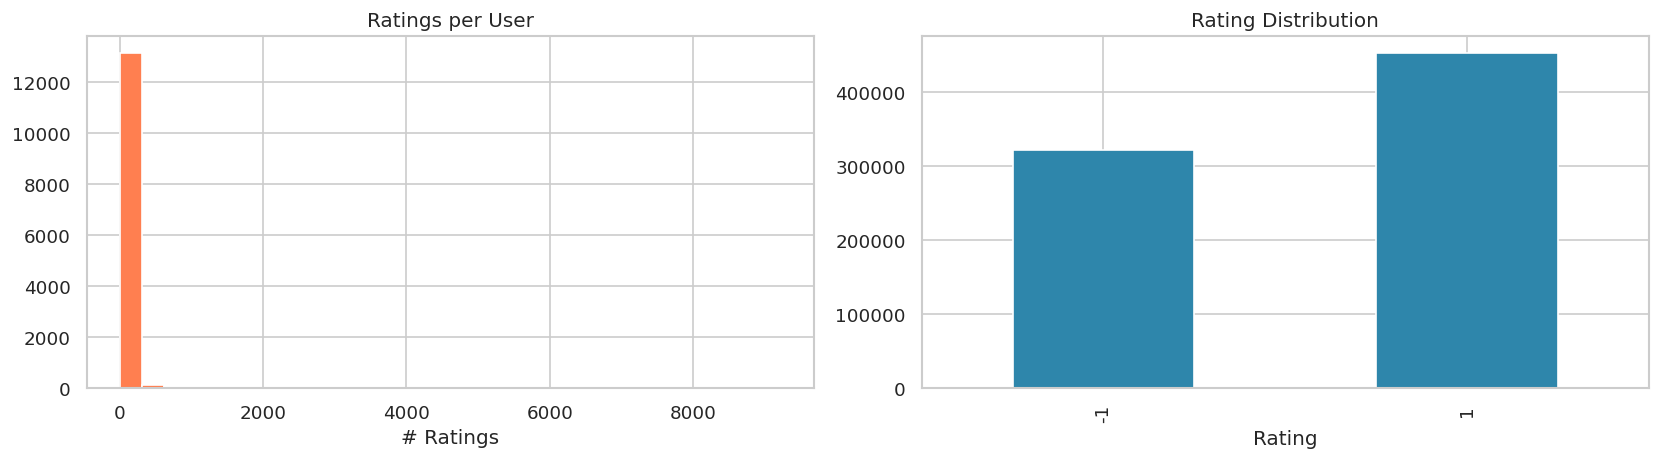

In [6]:
user_col   = next((c for c in ["user_id","userId","user"]   if c in rated_df.columns), None)
rating_col = next((c for c in ["rating","score","relevance"] if c in rated_df.columns), None)

print("Rated papers sample:"); print(rated_df.head(3))
print("\nImplicit interactions sample:"); print(implicit_df.head(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
if user_col:
    uc = rated_df[user_col].value_counts()
    print(f"\nTotal users: {uc.shape[0]} | Avg ratings/user: {uc.mean():.1f}")
    uc.hist(bins=30, ax=axes[0], color="coral", edgecolor="white")
    axes[0].set_title("Ratings per User"); axes[0].set_xlabel("# Ratings")
if rating_col:
    rated_df[rating_col].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#2E86AB")
    axes[1].set_title("Rating Distribution"); axes[1].set_xlabel("Rating")
    print(rated_df[rating_col].describe())
plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig_eda_interactions.png")
plt.show()

type_col = next((c for c in ["interaction_type","event","action","type"]
                 if c in implicit_df.columns), None)
if type_col:
    print("\nImplicit interaction types:"); print(implicit_df[type_col].value_counts())

## 6. Embedding Space Analysis

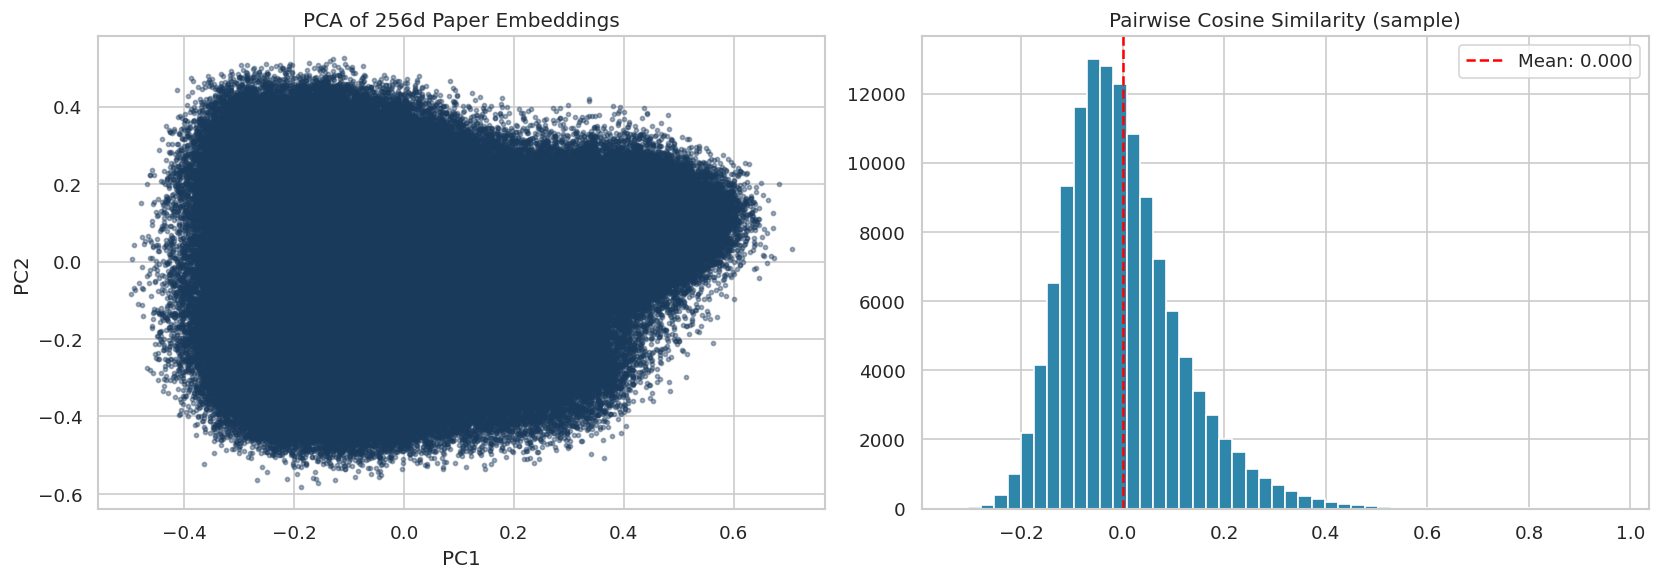

PCA explained variance: [0.052491   0.05000104]


In [7]:
emb_norm  = normalize(emb_256d, axis=1)
pca       = PCA(n_components=2, random_state=42)
coords    = pca.fit_transform(emb_norm)

sample_idx  = np.random.choice(len(emb_norm), size=min(500, len(emb_norm)), replace=False)
sim_matrix  = cosine_similarity(emb_norm[sample_idx])
upper       = sim_matrix[np.triu_indices_from(sim_matrix, k=1)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(coords[:, 0], coords[:, 1], s=6, alpha=0.4, c="#1A3A5C")
axes[0].set_title("PCA of 256d Paper Embeddings")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")

axes[1].hist(upper, bins=50, color="#2E86AB", edgecolor="white")
axes[1].set_title("Pairwise Cosine Similarity (sample)")
axes[1].axvline(np.mean(upper), color="red", linestyle="--",
                label=f"Mean: {np.mean(upper):.3f}")
axes[1].legend()

plt.tight_layout()
plt.savefig(REPORTS_DIR / "fig_embeddings.png")
plt.show()
print(f"PCA explained variance: {pca.explained_variance_ratio_}")

## 7. Data Quality Report, Dedup & Train/Val/Test Split

In [8]:
report = {
    "papers_total":            len(papers_df),
    "papers_with_abstract":    int(papers_df["abstract"].notna().sum()) if "abstract" in papers_df.columns else "N/A",
    "users_rated":             int(rated_df[user_col].nunique())  if user_col    else "N/A",
    "total_ratings":           len(rated_df),
    "total_implicit":          len(implicit_df),
    "embedding_dim_256":       emb_256d.shape[1],
    "embedding_dim_full":      emb_full.shape[1],
    "papers_with_embeddings":  emb_256d.shape[0],
}
for k, v in report.items():
    print(f"{k:35s}: {v}")

# ── Dedup ──────────────────────────────────────────────────────────────────────
id_col = next((c for c in ["paper_id","id","arxiv_id","paperId"] if c in papers_df.columns), None)
if id_col:
    dupes = papers_df[id_col].duplicated().sum()
    print(f"\nDuplicate paper IDs: {dupes}")
    if dupes > 0:
        papers_df = papers_df.drop_duplicates(subset=[id_col])
        print(f"After dedup: {len(papers_df)} papers")
papers_df.to_csv(OUTPUT_DIR / "cleaned_metadata.csv", index=False)
print("Saved: cleaned_metadata.csv")

# ── Train / Val / Test split — leave-one-out per user ─────────────────────────
if user_col and rating_col:
    sort_cols    = [user_col, "timestamp"] if "timestamp" in rated_df.columns else [user_col]
    rated_sorted = rated_df.sort_values(sort_cols)

    def split_by_user(group):
        n = len(group)
        if n < 3:
            return group.assign(split="train")
        n_test = max(1, int(round(n * TEST_FRAC)))
        n_val  = max(1, int(round(n * VAL_FRAC)))
        labels = ["train"] * (n - n_test - n_val) + ["val"] * n_val + ["test"] * n_test
        return group.assign(split=labels)

    rated_split = rated_sorted.groupby(user_col, group_keys=False).apply(split_by_user)
    print("\nData split:"); print(rated_split["split"].value_counts())
    rated_split.to_csv(OUTPUT_DIR / "rated_papers_split.csv", index=False)
    print("Saved: rated_papers_split.csv")
else:
    print("Cannot stratify: user_col or rating_col not found.")
    rated_split = rated_df

papers_total                       : 239618
papers_with_abstract               : 236094
users_rated                        : 13352
total_ratings                      : 774092
total_implicit                     : 556324
embedding_dim_256                  : 256
embedding_dim_full                 : 1024
papers_with_embeddings             : 239618

Duplicate paper IDs: 0
Saved: cleaned_metadata.csv

Data split:
split
train    541696
val      116198
test     116198
Name: count, dtype: int64
Saved: rated_papers_split.csv


## 8. Benchmark Construction Helpers

In [9]:
# == User profile builder ======================================================
def build_user_profile(user_papers: pd.DataFrame, papers_df: pd.DataFrame) -> Dict:
    """Build a user profile dict from interaction history."""
    pid_col = next((c for c in ["paper_id","paperId","arxiv_id","id"]
                    if c in user_papers.columns), None)
    if pid_col is None:
        return {"papers": [], "titles": [], "abstracts": []}
    paper_ids = user_papers[pid_col].tolist()
    meta      = papers_df[papers_df[pid_col].isin(paper_ids)] if pid_col in papers_df.columns else pd.DataFrame()
    return {
        "papers":    paper_ids,
        "titles":    meta["title"].dropna().tolist()    if "title"    in meta.columns else [],
        "abstracts": meta["abstract"].dropna().head(5).str[:200].tolist()
                     if "abstract" in meta.columns else [],
    }


# == Instance builder ==========================================================
def make_scireqa_instance(
    user_id,
    profile:     Dict,
    query:       str,
    query_type:  str,
    original_query: str,
    query_paper_id: str,
    gt_papers:   List[Dict],
    split:       str,
    domain:      str,
    hard_negatives:   Optional[List[Dict]] = None,
    difficulty_score: Optional[float]      = None,
    query_quality:    Optional[Dict]       = None,
) -> Dict:
    """
    Construct one SciRecQA instance (schema v1.1).

    v1.1 adds three fields populated by the enrichment pass (Section 16.5):
      hard_negatives   - topically similar papers NOT in GT (ranking difficulty)
      difficulty_score - inverse similarity between query and GT (higher = harder)
      query_quality    - rule-based sub-scores (length / specificity / type_fit)

    hallucination_labels and entity_verification are populated later
    (after rationale generation). The domain is included in the MD5 hash to
    guarantee uniqueness across all three corpora.
    """
    instance_id = hashlib.md5(
        f"{domain}_{user_id}_{query_paper_id}".encode()
    ).hexdigest()[:12]

    return {
        "id":                   instance_id,
        "benchmark_version":    BENCHMARK_VERSION,
        "construction_date":    CONSTRUCTION_DATE,
        "domain":               domain,
        "split":                split,
        "annotation_status":    "pending_human",

        "user_id":              str(user_id),
        "user_profile":         profile,

        "query":                query,
        "query_type":           query_type,
        "original_query":       original_query,
        "query_paper_id":       str(query_paper_id),
        "ground_truth_papers":  gt_papers,
        "hard_negatives":       hard_negatives if hard_negatives is not None else [],
        "difficulty_score":     difficulty_score,
        "query_quality":        query_quality if query_quality is not None else {},

        "reference_rationale":  "",
        "rationale_metadata":   {
            "model":           RATIONALE_MODEL,
            "generated":       False,
            "generation_date": None,
        },

        "hallucination_labels": [],
        "entity_verification":  {
            "total_cited":          0,
            "verified":             0,
            "unverified":           [],
            "citation_trust_score": 1.0,
        },
    }


## 9. Query Generation

**Fix**: the original notebook used raw paper abstracts (250+ words) as
`history_based` queries. No user types a full abstract into a recommender.
This cell provides `make_realistic_query()` which generates short, natural
queries that reflect actual user behaviour patterns observed in academic
recommender user studies.

In [10]:
_QUERY_STOP = {"the","a","an","of","for","and","with","using","via","on","in",
               "to","from","by","based","we","our","this","study","paper"}

def _top_profile_keyword(profile: Dict) -> str:
    """Longest content word from the most recent profile title (personalisation)."""
    for t in reversed(profile.get("titles", []) or []):
        words = [w for w in re.findall(r"[A-Za-z][A-Za-z\-]{3,}", str(t))
                 if w.lower() not in _QUERY_STOP]
        if words:
            return max(words, key=len)
    return ""


def make_realistic_query(
    paper:      Dict,
    query_type: str,
    profile:    Dict,
    domain:     str,
) -> Tuple[str, str]:
    """
    Generate an ecologically valid user query (max QUERY_MAX_LEN chars).

    v1.1: guarantees a NON-EMPTY query via a fallback cascade
          (title/abstract -> categories/venue -> arxiv_id -> profile keyword),
          fixing the 564 empty arXiv queries in v1.0.

    Returns (query, original_query).
    """
    title    = (paper.get("title",    "") or "").strip()
    abstract = (paper.get("abstract", "") or "").strip()
    cats     = str(paper.get("categories", paper.get("venue", "")) or "").strip()
    aid      = str(paper.get("arxiv_id", paper.get("paperId", "")) or "").strip()
    kw       = _top_profile_keyword(profile)

    # First meaningful sentence of the abstract
    first_sent = ""
    if abstract:
        sents = [s.strip() for s in re.split(r'(?<=[.!?])\s+', abstract)
                 if len(s.strip()) > 15]
        first_sent = sents[0][:120] if sents else abstract[:120]

    if query_type == "history_based":
        if title:
            q = f'I recently read "{title[:80]}". {first_sent} Recommend similar papers.'
        elif first_sent:
            q = f"{first_sent} Recommend similar papers."
        elif cats:
            q = f"Recommend recent {cats} papers similar to my recent reading."
        elif aid:
            q = f"Recommend papers similar to arXiv:{aid}."
        else:
            q = f"Recommend papers on {kw or 'my research topics'}."
        original = title or abstract[:100] or cats or aid

    elif query_type == "natural_language":
        keywords = str(paper.get("keywords", "") or "")[:120]
        if keywords:
            q = f"Papers on: {keywords}"
        elif cats and first_sent:
            q = f"Recent advances in {cats[:80]} related to: {first_sent[:80]}"
        elif first_sent:
            q = first_sent[:QUERY_MAX_LEN]
        elif cats:
            q = f"Recent advances in {cats[:120]}"
        elif aid:
            q = f"Papers related to arXiv:{aid}"
        else:
            q = f"Papers on {kw or 'this topic'}"
        original = q

    else:  # hybrid
        kws    = (profile.get("keywords") or profile.get("titles") or [])[:3]
        kw_str = ", ".join(str(k)[:30] for k in kws) if kws else ""
        if title and kw_str:
            q = f'More papers like "{title[:60]}" intersecting {kw_str}'
        elif title:
            q = f'More papers like "{title[:80]}"'
        elif first_sent:
            q = first_sent[:QUERY_MAX_LEN]
        elif cats:
            q = f"More papers in {cats[:120]}"
        elif aid:
            q = f"More papers like arXiv:{aid}"
        else:
            q = f"More papers on {kw or 'my research topics'}"
        original = title or q

    q = (q or "").strip() or "Recommend related scientific papers."
    original = (original or q).strip()
    return q[:QUERY_MAX_LEN], original[:QUERY_MAX_LEN]


## 10. Semantic Scholar API — Helpers

In [11]:
def fetch_s2_paper(
    paper_id:    str,
    fields:      str = "paperId,title,authors,year,venue,abstract,citationCount",
    _retries:    int = 0,
    max_retries: int = 3,
) -> Optional[Dict]:
    """Fetch a single paper record from Semantic Scholar with exponential back-off."""
    url = f"{S2_BASE}/paper/{paper_id}"
    try:
        resp = requests.get(url, headers=S2_HDRS, params={"fields": fields}, timeout=10)
        if resp.status_code == 200:
            return resp.json()
        if resp.status_code == 429 and _retries < max_retries:
            time.sleep(2 ** (_retries + 1))
            return fetch_s2_paper(paper_id, fields, _retries + 1, max_retries)
    except requests.RequestException:
        pass
    return None


def search_s2_papers(
    query:           str,
    fields_of_study: Optional[List[str]] = None,
    limit:           int = 20,
    _retries:        int = 0,
    max_retries:     int = 3,
) -> List[Dict]:
    """Search Semantic Scholar for papers matching a query."""
    params = {
        "query":  query,
        "limit":  limit,
        "fields": "paperId,title,authors,year,venue,abstract,citationCount",
    }
    if fields_of_study:
        params["fieldsOfStudy"] = ",".join(fields_of_study)
    try:
        resp = requests.get(f"{S2_BASE}/paper/search",
                            headers=S2_HDRS, params=params, timeout=15)
        if resp.status_code == 200:
            return resp.json().get("data", [])
        if resp.status_code == 429 and _retries < max_retries:
            time.sleep(2 ** (_retries + 1))
            return search_s2_papers(query, fields_of_study, limit, _retries + 1, max_retries)
    except requests.RequestException:
        pass
    return []


def enrich_with_citations(
    paper_id: str,
    title:    str = "",
    limit:    int = 5,
) -> List[Dict]:
    """Fetch papers that cite `paper_id` — used to enrich ground-truth sets."""
    if paper_id:
        url  = f"{S2_BASE}/paper/{paper_id}/citations"
        resp = requests.get(
            url, headers=S2_HDRS,
            params={"fields": "paperId,title,abstract,year,venue,authors", "limit": limit},
            timeout=10,
        )
        if resp.status_code == 200:
            return [e["citingPaper"] for e in resp.json().get("data", []) if e.get("citingPaper")]
    # Fallback: text search on title
    return search_s2_papers(title, limit=limit) if title else []

print("S2 helper functions defined.")

S2 helper functions defined.


## 11. Grounding-Label Backend (MiniCheck / NLI fallback)

Loads the **MiniCheck** fact-checker (Tang et al., EMNLP 2024) — a model built
specifically to decide whether a *claim* is grounded in a *document* — to label
each atomic claim of a reference rationale. If MiniCheck is unavailable, the
pipeline falls back to a strong generic NLI model
(`MoritzLaurer/DeBERTa-v3-large-mnli-fever-anli-ling-wanli`); if neither loads,
factual claims are marked `pending_annotation`.

**Why MiniCheck rather than generic NLI?** The task is claim-grounded-in-document
verification (each claim is checked against several GT abstracts), which is exactly
what MiniCheck is trained for — unlike sentence-pair MNLI models. It is efficient
(runs on a T4/P100), reproducible (pinned open weights), and its support
probability is **calibrated against the human gold subset** in `agentic-nb2`.
These auto labels are *silver*; the human-verified subset is *gold*.

In [12]:
# ── Grounding-label backend: MiniCheck (default) or generic NLI (fallback) ─────
_NLI_MAP = {"ENTAILMENT": "supported", "CONTRADICTION": "unsupported", "NEUTRAL": "neutral"}


def setup_minicheck():
    """Load MiniCheck (Tang et al. 2024): a claim-grounded-in-document fact-checker.
    Returns a scorer, or None for graceful degradation."""
    if LABELER != "minicheck":
        return None
    try:
        from minicheck.minicheck import MiniCheck
        scorer = MiniCheck(model_name=MINICHECK_MODEL, enable_prefix_caching=False)
        _ = scorer.score(docs=["The sky is blue."], claims=["The sky is blue."])  # warm-up
        print(f"MiniCheck ready : {MINICHECK_MODEL}  (claim-grounded fact-checker)")
        return scorer
    except Exception as e:
        print(f"MiniCheck unavailable ({e}) - falling back to NLI/pending.")
        return None


def setup_nli_pipeline():
    """Load the generic-NLI fallback. Returns None on failure (graceful degradation)."""
    try:
        from transformers import pipeline as hf_pipeline
        nli = hf_pipeline("text-classification", model=NLI_MODEL_NAME,
                          device=0 if torch.cuda.is_available() else -1,
                          truncation=True, max_length=512)
        _ = nli({"text": "The sky is blue.", "text_pair": "The sky has colour."})
        print(f"NLI fallback ready : {NLI_MODEL_NAME}")
        return nli
    except Exception as e:
        print(f"NLI pipeline unavailable ({e}); factual claims -> 'pending_annotation'.")
        return None


minicheck_scorer = setup_minicheck()
# Load NLI only when it will actually be used (MiniCheck off/unavailable) to save VRAM.
nli_pipeline = setup_nli_pipeline() if (LABELER == "nli" or minicheck_scorer is None) else None
_BACKEND = ("minicheck" if minicheck_scorer is not None
            else "nli" if nli_pipeline is not None else "pending")
print(f"Active labeling backend: {_BACKEND}")


def decompose_to_claims(text: str) -> List[str]:
    """Split a rationale into atomic claim sentences."""
    raw = re.split(r'(?<=[.!?])\s+', text.strip())
    return [s.strip() for s in raw if len(s.strip()) >= MIN_CLAIM_LEN]


# Rule-based claim typing (v1.1): only verifiable factual claims hit the model;
# generic prose is labelled 'general_statement' without a model call.
_RE_YEAR   = re.compile(r"\b(19|20)\d{2}\b")
_RE_NUM    = re.compile(r"\d")
_RE_QUOTE  = re.compile(r"[\"“”]")
_RE_METRIC = re.compile(r"\b(\d+(\.\d+)?\s?%|accuracy|f1|bleu|rouge|map|ndcg|precision|"
                        r"recall|score|state[- ]of[- ]the[- ]art|sota|outperform|baseline|dataset)\b",
                        re.IGNORECASE)
_RE_PROPER = re.compile(r"\b([A-Z][a-zA-Z]+(?:\s+[A-Z][a-zA-Z]+)+)\b")

def classify_claim_type(claim: str) -> str:
    if (_RE_QUOTE.search(claim) or _RE_YEAR.search(claim) or _RE_METRIC.search(claim)
            or _RE_NUM.search(claim) or _RE_PROPER.search(claim)):
        return "factual_candidate"
    return "general_statement"


# --- Relational-claim detection: the CiteCheck target (plan §5-§6) -------------
# A relational claim asserts a relationship BETWEEN papers (builds_on / compares /
# shares_topic / supersedes) that text-only verifiers cannot check from a single
# sentence. We flag it and extract (paper_a, relation, paper_b) for graph verification.
_REL_CUES = {
    "builds_on":    ["builds on", "build on", "based on", "extends", "extension of",
                     "inspired by", "leverages", "follows from", "draws on", "grounded in"],
    "compares":     ["outperforms", "compared to", "compared with", "in contrast", "unlike",
                     "better than", " versus ", " vs ", "improves over", "baseline"],
    "shares_topic": ["both ", "similarly", "also addresses", "shares ", "same ",
                     "related to", "in line with", "complements"],
    "supersedes":   ["supersedes", "replaces", "improves upon", "succeeds"],
}

def _rel_toks(txt):
    return {w.lower() for w in re.findall(r"[A-Za-z][A-Za-z\-]{2,}", str(txt))}

def _match_titles(claim, gt_papers, k=2):
    """Return up to k GT paper_ids whose title is quoted in / strongly overlaps the claim."""
    quoted = re.findall(r'[\"“”]([^\"“”]{6,})[\"“”]', claim)
    claim_tok = _rel_toks(claim)
    found = []
    for p in gt_papers:
        t = (p.get("title", "") or "").strip()
        if not t:
            continue
        tl = t.lower()
        hit = any(q.lower()[:40] in tl or tl[:40] in q.lower() for q in quoted)
        if not hit:
            tt = _rel_toks(t)
            if tt and len(tt & claim_tok) / len(tt) >= 0.6:
                hit = True
        if hit:
            found.append(p.get("paper_id", ""))
        if len(found) >= k:
            break
    return found

def detect_relation(claim, gt_papers):
    """Detect a relational claim; extract (paper_a, relation, paper_b) when possible.
    Returns None for non-relational claims."""
    cl = " " + claim.lower() + " "
    relation = next((rel for rel, cues in _REL_CUES.items()
                     if any(cue in cl for cue in cues)), None)
    if relation is None:
        return None
    papers = _match_titles(claim, gt_papers)
    return {
        "is_relational": True,
        "relation":      relation,
        "paper_a":       papers[0] if len(papers) >= 1 else None,
        "paper_b":       papers[1] if len(papers) >= 2 else None,
    }


def _build_evidence(gt_papers: List[Dict], max_chars: int) -> str:
    parts = []
    for p in gt_papers[:5]:
        title = (p.get("title", "") or "").strip()
        abst  = (p.get("abstract", "") or "").strip()
        year  = p.get("year", ""); venue = p.get("venue", "") or ""
        if abst:
            parts.append(f"{title} ({year}, {venue}): {abst[:400]}")
        elif title:
            parts.append(f"{title} ({year})")
    return " ".join(parts)[:max_chars]


def _verdict_from_prob(p):
    """Map a MiniCheck support probability to a verdict. Thresholds are calibrated
    on the human gold subset (agentic-nb2). 'confidence' stores the RAW prob."""
    p = float(p)
    if p >= MINICHECK_SUPPORT_THRESHOLD:
        v = "supported"
    elif p < MINICHECK_UNSUPPORT_THRESHOLD:
        v = "unsupported"
    else:
        v = "neutral"
    return v, round(p, 4), "auto_minicheck", f"MiniCheck-{MINICHECK_MODEL}"


def generate_hallucination_labels(rationale: str, gt_papers: List[Dict]) -> List[Dict]:
    """Sentence-level grounding labels (SciRecQA v1.1).
    Factual claims are scored by MiniCheck (or the NLI fallback); generic prose is
    labelled 'general_statement' by rule. Each label carries a 'claim_type'."""
    if (not rationale or rationale.startswith("[PLACEHOLDER")
            or rationale.startswith("[ERROR") or rationale.startswith("[NO_")):
        return []

    # MiniCheck handles long docs internally; the NLI fallback is capped at 512 tokens.
    evidence = _build_evidence(gt_papers, 4000 if minicheck_scorer is not None else 2048)
    if not evidence:
        return []

    claims = decompose_to_claims(rationale)
    if not claims:
        return []
    types = [classify_claim_type(c) for c in claims]
    factual_idx = [i for i, t in enumerate(types) if t == "factual_candidate"]

    scored = {}   # idx -> (verdict, confidence, label_type, model)
    if factual_idx:
        f_claims = [claims[i] for i in factual_idx]
        if minicheck_scorer is not None:
            try:
                _, probs, _, _ = minicheck_scorer.score(docs=[evidence] * len(f_claims),
                                                        claims=f_claims)
                for i, prob in zip(factual_idx, probs):
                    scored[i] = _verdict_from_prob(prob)
            except Exception:
                for i in factual_idx:
                    scored[i] = ("neutral", 0.0, "auto_minicheck_error", f"MiniCheck-{MINICHECK_MODEL}")
        elif nli_pipeline is not None:
            for i in factual_idx:
                try:
                    r = nli_pipeline({"text": evidence, "text_pair": claims[i]},
                                     truncation=True, max_length=512)
                    verdict = _NLI_MAP.get(r.get("label", "NEUTRAL").upper(), "neutral")
                    scored[i] = (verdict, round(float(r.get("score", 0.0)), 4), "auto_nli", NLI_MODEL_NAME)
                except Exception:
                    scored[i] = ("neutral", 0.0, "auto_nli_error", NLI_MODEL_NAME)
        else:
            for i in factual_idx:
                scored[i] = ("pending_annotation", 0.0, "pending", None)

    labels = []
    for i, (claim, ctype) in enumerate(zip(claims, types)):
        if ctype == "general_statement":
            verdict, conf, ltype, model_name = "general_statement", 0.0, "rule_general", None
        else:
            verdict, conf, ltype, model_name = scored.get(i, ("pending_annotation", 0.0, "pending", None))
        labels.append({
            "claim_id":       f"{i:03d}",
            "claim_text":     claim,
            "claim_type":     ctype,
            "relational":     detect_relation(claim, gt_papers),
            "verdict":        verdict,
            "confidence":     conf,
            "label_type":     ltype,
            "model":          model_name,
            "human_verified": False,
            "human_label":    None,
        })
    return labels


config.json:   0%|          | 0.00/826 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/3.13G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/560 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/3.13G [00:00<?, ?B/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie shared.weight to encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie shared.weight to decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


generation_config.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

... (3 outputs left out)

added_tokens.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

Evaluating: 100%|██████████| 1/1 [00:01<00:00,  1.70s/it]

MiniCheck ready : flan-t5-large  (claim-grounded fact-checker)
Active labeling backend: minicheck


## 12. Entity Verification Helper

Checks whether paper titles *quoted* inside a rationale are verifiable against
the ground-truth paper set. This produces `citation_trust_score ∈ [0, 1]`
per instance — one of the novel metrics reported in the MAPER paper.

In [13]:
def verify_cited_entities(rationale: str, gt_papers: List[Dict]) -> Dict:
    """
    Verify whether entity mentions (quoted titles) in the rationale
    match actual ground-truth papers.

    Approach: extract all double-quoted strings; match loosely against
    GT paper titles using a normalised substring check.
    Returns a dict that populates the `entity_verification` field.
    """
    if not rationale:
        return {"total_cited": 0, "verified": 0, "unverified": [],
                "citation_trust_score": 1.0}

    gt_titles_norm = {p.get("title", "").lower().strip() for p in gt_papers if p.get("title")}
    quoted         = re.findall(r'\"([^\"]{10,})\"', rationale)  # strings >=10 chars

    verified   = 0
    unverified = []
    for q in quoted:
        q_norm = q.lower().strip()
        if any(q_norm in t or t in q_norm for t in gt_titles_norm):
            verified += 1
        else:
            unverified.append(q)

    total = len(quoted)
    return {
        "total_cited":          total,
        "verified":             verified,
        "unverified":           unverified,
        "citation_trust_score": round(verified / total, 4) if total > 0 else 1.0,
    }

## 13. Reference Rationale Generation (Llama-3.3-70B via OpenRouter)

In [14]:
# == Domain-specific prompt templates =========================================
RATIONALE_PROMPTS = {
    "arxiv_cs": (
        "You are an expert computer-science researcher. A user read the paper below "
        "and wants similar recommendations. Write a 3-4 sentence rationale explaining "
        "WHY the recommended papers are relevant to the user's interests. "
        "Ground every claim in the provided abstracts. "
        "Do NOT fabricate paper titles, authors, or results.\n\n"
        "User query: {query}\n\n"
        "Recommended papers:\n{papers}\n\n"
        "Rationale:"
    ),
    "acl_anthology": (
        "You are an NLP researcher. Write a 3-4 sentence rationale explaining "
        "why the recommended NLP papers match the user query below. "
        "Ground every claim in the provided abstracts. "
        "Do NOT fabricate paper titles, authors, venues, or results.\n\n"
        "User query: {query}\n\n"
        "Recommended papers:\n{papers}\n\n"
        "Rationale:"
    ),
    "pubmed": (
        "You are a biomedical literature expert. Write a 3-4 sentence rationale "
        "explaining why the recommended papers are relevant to the clinical/biomedical "
        "query below. Ground every claim in the provided abstracts. "
        "Do NOT fabricate paper titles, authors, or clinical findings.\n\n"
        "User query: {query}\n\n"
        "Recommended papers:\n{papers}\n\n"
        "Rationale:"
    ),
}


# == v2: relation-eliciting mode (plan P0/P1) =================================
# RATIONALE_MODE "relational" makes the Solver state INTER-PAPER relations
# (builds_on / compares / uses_method_of / supersedes) so detect_relation (cell 23)
# and CiteCheck (notebook 04) have material to verify. "relevance" = original prompts.
RATIONALE_MODE = "relational"      # "relational" | "relevance"
SUBSET_N       = None              # full 10k run (reproduces the shipped artifact). Was 100 for the P0 prototype.
# NOTE: relational rationales are longer; if outputs look truncated, raise
# RATIONALE_MAX_TOKENS (cell 3) from 300 to ~500.

_REL_INSTRUCTION = (
    "In 3-5 sentences, explain how the recommended papers relate TO EACH OTHER and to the "
    "query paper. Where the abstracts support it, state explicit relationships using these "
    "relation cues: 'builds on'/'extends'/'based on' (one paper builds on or extends another), "
    "'outperforms'/'compared to'/'in contrast to' (one paper compares to or outperforms another), "
    "'uses the method of' (one paper uses another's method), or 'supersedes'/'improves upon'. "
    "Refer to each paper by its number and exact title in quotes, e.g. paper [2] \"Title\". "
    "Ground every claim in the provided abstracts; do NOT fabricate titles, authors, results, or relationships."
)
RATIONALE_PROMPTS_RELATIONAL = {
    "arxiv_cs": (
        "You are an expert computer-science researcher. " + _REL_INSTRUCTION +
        "\n\nUser query: {query}\n\nQuery and recommended papers:\n{papers}\n\nRelational rationale:"
    ),
    "acl_anthology": (
        "You are an NLP researcher. " + _REL_INSTRUCTION +
        "\n\nUser query: {query}\n\nQuery and recommended papers:\n{papers}\n\nRelational rationale:"
    ),
    "pubmed": (
        "You are a biomedical literature expert. " + _REL_INSTRUCTION +
        "\n\nUser query: {query}\n\nQuery and recommended papers:\n{papers}\n\nRelational rationale:"
    ),
}


def _format_papers_for_prompt(gt_papers: List[Dict], max_papers: int = 5) -> str:
    lines = []
    for i, p in enumerate(gt_papers[:max_papers], 1):
        title    = p.get("title",    "Unknown")
        abstract = (p.get("abstract", "") or "")[:300]
        year     = p.get("year",    "")
        venue    = p.get("venue",   "") or ""
        lines.append(f'[{i}] "{title}" ({year}, {venue})\n    {abstract}')
    return "\n\n".join(lines)


def _openrouter_provider_routing():
    """Pin a single host so all rationales share quantization + serving config."""
    routing = {
        "order": [OPENROUTER_PROVIDER],                 # only this provider...
        "allow_fallbacks": OPENROUTER_ALLOW_FALLBACKS,  # ...no silent switch to another host
        "require_parameters": True,                     # drop host if it ignores temperature/seed/max_tokens
    }
    if OPENROUTER_QUANT:
        routing["quantizations"] = [OPENROUTER_QUANT]
    return routing


def generate_rationale(
    query:     str,
    gt_papers: List[Dict],
    profile:   Dict,
    domain:    str,
) -> Tuple[str, bool, Optional[str]]:
    """
    Generate a grounded reference rationale via Llama-3.3-70B-Instruct on a SINGLE
    pinned OpenRouter host (no auto-routing) for benchmark-wide consistency.
    Returns (rationale_text, success_flag, served_by_provider).
    """
    if not OPENROUTER_API_KEY:
        return "[NO_OPENROUTER_KEY]", False, None

    papers_str = _format_papers_for_prompt(gt_papers)
    _PROMPTS   = RATIONALE_PROMPTS_RELATIONAL if RATIONALE_MODE == "relational" else RATIONALE_PROMPTS
    prompt     = _PROMPTS.get(domain, _PROMPTS["arxiv_cs"]).format(
        query=query, papers=papers_str
    )
    try:
        import openai
        client   = openai.OpenAI(api_key=OPENROUTER_API_KEY, base_url=OPENROUTER_BASE_URL)
        response = client.chat.completions.create(
            model=RATIONALE_MODEL,
            messages=[{"role": "user", "content": prompt}],
            max_tokens=RATIONALE_MAX_TOKENS,
            temperature=RATIONALE_TEMPERATURE,
            seed=RATIONALE_SEED,
            extra_body={"provider": _openrouter_provider_routing()},
        )
        served = (getattr(response, "model_extra", None) or {}).get("provider")  # actual host used
        text   = (response.choices[0].message.content or "").strip()
        if not text:
            return "[ERROR: empty completion]", False, served
        return text, True, served
    except Exception as e:
        return f"[ERROR: {e}]", False, None


# Back-compat alias (older cells referenced this name)
generate_rationale_gpt4o = generate_rationale


# == Checkpoint helpers ========================================================
def _load_checkpoint(path: Path) -> dict:
    """Safely load a JSON checkpoint (missing / empty / corrupt -> {})."""
    if not path.exists():
        return {}
    try:
        raw = path.read_text(encoding="utf-8").strip()
        if not raw:
            print(f"Checkpoint {path.name} is empty (crashed write) - starting fresh.")
            return {}
        return json.loads(raw)
    except json.JSONDecodeError as exc:
        print(f"Checkpoint {path.name} corrupted ({exc}) - starting fresh.")
        return {}

print("Rationale helpers defined (OpenRouter / Llama-3.3-70B).")


Rationale helpers defined (OpenRouter / Llama-3.3-70B).


## 14. Construct SciRecQA — arXiv CS Subset

For each user in the rated split:
- Profile = all their rated papers (excluding the query anchor)
- Query anchor = their most recent rated paper
- GT papers = remaining rated papers (MIN_GT_PAPERS <= |GT| <= MAX_GT_PAPERS)
- Query type alternates between `history_based` and `hybrid` (50 / 50)

In [15]:
# == Build SciRecQA arXiv CS instances (v1.1) =================================
# Root-cause fix vs v1.0:
#   (1) ONLY positively-rated papers (rating > 0) enter the profile AND the GT
#       -> no more papers the user explicitly disliked (rating == -1) as GT.
#   (2) GT is a TEMPORAL HOLD-OUT: the later band of the user's positives, held
#       out from the EARLIER positives shown in the profile. GT is therefore
#       DISJOINT from the visible profile (fixes 100% GT==profile leakage) and
#       every GT paper precedes the query in time (GT year <= query year).
import random as _rnd
_rnd.seed(42)

# Fast metadata lookup (avoids per-row DataFrame scans)
_pidx = papers_df.drop_duplicates(subset=["arxiv_id"]).set_index("arxiv_id") \
        if "arxiv_id" in papers_df.columns else None

def _meta_for(pid):
    if _pidx is not None and pid in _pidx.index:
        return _pidx.loc[pid].dropna().to_dict()
    return {}

def _gt_record(pid):
    m = _meta_for(pid)
    return {
        "paper_id": str(pid),
        "title":    str(m.get("title", "")),
        "abstract": str(m.get("abstract", ""))[:500],
        "year":     str(m.get("published", m.get("year", "")))[:10],
        "venue":    "",
        "authors":  [],
    }

# Positive ratings only, chronological
rated_pos = rated_df[rated_df["rating"] > 0].copy()
if "time" in rated_pos.columns:
    rated_pos = rated_pos.sort_values("time")

arxiv_instances = []
dropped_few = 0
for i, (uid, g) in enumerate(tqdm(rated_pos.groupby("user_id", sort=False),
                                  desc="arXiv CS instances")):
    pids = g["arxiv_id"].astype(str).tolist()          # chronological
    if len(pids) < PROFILE_MIN_PAPERS + MIN_GT_PAPERS + 1:
        dropped_few += 1
        continue

    query_pid    = pids[-1]                  # most recent positive = query paper
    rest         = pids[:-1]
    max_gt       = min(GT_SAMPLE_MAX, len(rest) - PROFILE_MIN_PAPERS)
    gt_size      = _rnd.randint(GT_SAMPLE_MIN, max_gt)
    gt_pids      = rest[-gt_size:]           # LATER positives  -> held-out GT
    profile_pids = rest[:-gt_size]           # EARLIER positives -> visible history

    prof_meta = [(pid, _meta_for(pid)) for pid in profile_pids]
    profile = {
        "papers":    profile_pids,
        "titles":    [str(m.get("title", "")) for _, m in prof_meta if m.get("title")],
        "abstracts": [str(m.get("abstract", ""))[:200] for _, m in prof_meta if m.get("abstract")][:5],
    }

    gt_papers = [r for r in (_gt_record(pid) for pid in gt_pids) if r["paper_id"]]
    if len(gt_papers) < MIN_GT_PAPERS:
        continue

    # Hard invariant: GT must never be visible in the profile
    assert not ({p["paper_id"] for p in gt_papers} & set(profile_pids)), "GT/profile leakage!"

    query_meta = _meta_for(query_pid)
    query_meta.setdefault("arxiv_id", query_pid)
    qtype = "history_based" if i % 2 == 0 else "hybrid"
    query_q, orig_q = make_realistic_query(query_meta, qtype, profile, "arxiv_cs")

    arxiv_instances.append(make_scireqa_instance(
        user_id        = uid,
        profile        = profile,
        query          = query_q,
        query_type     = qtype,
        original_query = orig_q,
        query_paper_id = query_pid,
        gt_papers      = gt_papers,
        split          = "train",            # re-balanced to 70/15/15 in Section 20
        domain         = "arxiv_cs",
    ))
    if len(arxiv_instances) >= TARGET_ARXIV:
        break

gt_counts = [len(x["ground_truth_papers"]) for x in arxiv_instances]
_leak = sum(1 for x in arxiv_instances
            if {p['paper_id'] for p in x['ground_truth_papers']} & set(x['user_profile']['papers']))
print(f"Built {len(arxiv_instances)} arXiv CS instances "
      f"(dropped {dropped_few} users with too few positives)")
print(f"  GT papers -> min:{min(gt_counts)} mean:{sum(gt_counts)/max(1,len(gt_counts)):.2f} max:{max(gt_counts)}")
print(f"  GT/profile overlap instances : {_leak}  (must be 0)")
print(f"  Query types: {Counter(x['query_type'] for x in arxiv_instances)}")


arXiv CS instances:  56%|█████▋    | 7320/12957 [00:39<00:30, 187.66it/s]

Built 6000 arXiv CS instances (dropped 1321 users with too few positives)
  GT papers -> min:3 mean:5.32 max:8
  GT/profile overlap instances : 0  (must be 0)
  Query types: Counter({'hybrid': 3017, 'history_based': 2983})


## 15. Fetch ACL Anthology Papers via Semantic Scholar API

In [16]:
ACL_QUERIES = [
    "retrieval augmented generation hallucination",
    "large language models recommendation systems",
    "multi-agent NLP reasoning",
    "knowledge graph question answering",
    "scientific paper recommendation personalization",
    "direct preference optimization language models",
    "chain of thought reasoning verification",
    "citation network paper recommendation",
    "factual consistency evaluation NLP",
    "transformer attention scientific text",
    "question answering reading comprehension BERT",
    "text generation controllable language model",
    "cross-lingual transfer learning multilingual",
    "summarization abstractive extractive neural",
    "dialogue systems conversational AI",
    "semantic parsing structured prediction",
    "machine translation neural sequence to sequence",
    "sentiment analysis opinion mining reviews",
    "coreference resolution entity linking NLP",
    "information retrieval dense passage retrieval",
    "event extraction relation classification",
    "argument mining persuasion detection",
    "commonsense reasoning knowledge graph NLP",
    "document ranking passage retrieval neural",
    "text classification topic modeling neural",
    "natural language inference entailment",
    "named entity recognition sequence labeling",
    "paraphrase detection sentence similarity",
    "open domain question answering retrieval",
    "low resource NLP few shot learning",
    "prompt tuning in-context learning LLM",
    "instruction tuning RLHF alignment",
    "hallucination detection LLM factuality",
    "long document understanding transformer",
    "code generation program synthesis LLM",
    "multimodal vision language model",
    "discourse coherence paragraph structure",
    "bias fairness NLP language model",
    "explainability interpretability NLP attention",
    "data augmentation low resource text classification",
]

acl_papers_raw = []
seen_ids        = set()

for q in tqdm(ACL_QUERIES, desc="Fetching ACL papers"):
    results = search_s2_papers(q, fields_of_study=["Computer Science"], limit=90)
    for p in results:
        pid = p.get("paperId")
        if pid and pid not in seen_ids:
            # Keep only papers with abstracts
            if p.get("abstract"):
                acl_papers_raw.append(p)
                seen_ids.add(pid)
    time.sleep(0.5)   # respect S2 rate limit

print(f"Fetched {len(acl_papers_raw)} unique ACL papers with abstracts")

# Save raw fetch
with open(OUTPUT_DIR / "acl_papers_raw.json", "w") as f:
    json.dump(acl_papers_raw, f)
print("Saved acl_papers_raw.json")

Fetching ACL papers: 100%|██████████| 40/40 [02:11<00:00,  3.29s/it]

Fetched 2869 unique ACL papers with abstracts
Saved acl_papers_raw.json


In [17]:
# == Build ACL instances (v1.1) ===============================================
#   query_type = 'natural_language'; user = simulated (previous 5 papers in fetch
#   order). v1.1: GT size sampled in [GT_SAMPLE_MIN, GT_SAMPLE_MAX] (variance),
#   GT excludes profile papers, and GT year <= query year (temporal hold-out).
import random as _rnd
_rnd.seed(42)

def _parse_year(v):
    m = re.search(r"(19|20)\d{2}", str(v))
    return int(m.group(0)) if m else None

acl_instances = []
n_acl         = len(acl_papers_raw)
pbar          = tqdm(total=min(TARGET_ACL, n_acl - 1), desc="ACL instances")

for n, paper in enumerate(acl_papers_raw):
    if len(acl_instances) >= TARGET_ACL:
        break
    try:
        paper_id    = paper.get("paperId", f"acl_{n}")
        start       = max(0, n - 5)
        prof_papers = acl_papers_raw[start:n]
        profile = {
            "papers":    [p.get("paperId", "") for p in prof_papers],
            "titles":    [p.get("title",   "") for p in prof_papers],
            "abstracts": [(p.get("abstract", "") or "")[:200] for p in prof_papers],
        }
        prof_ids = set(profile["papers"])
        q_year   = _parse_year(paper.get("year", ""))
        gt_size  = _rnd.randint(GT_SAMPLE_MIN, GT_SAMPLE_MAX)

        gt_papers = []
        for p in acl_papers_raw[n + 1:]:
            if len(gt_papers) >= gt_size:
                break
            if not p.get("abstract") or p.get("paperId") in prof_ids:
                continue
            py = _parse_year(p.get("year", ""))
            if q_year and py and py > q_year:          # no future leakage
                continue
            gt_papers.append({
                "paper_id": p.get("paperId", ""),
                "title":    p.get("title",   ""),
                "abstract": (p.get("abstract", "") or "")[:500],
                "year":     p.get("year",  ""),
                "venue":    p.get("venue", "") or "",
                "authors":  [a.get("name", "") for a in p.get("authors", [])][:5],
            })

        if len(gt_papers) < MIN_GT_PAPERS:
            continue

        query_q, orig_q = make_realistic_query(paper, "natural_language", profile, "acl_anthology")
        acl_instances.append(make_scireqa_instance(
            user_id        = f"acl_user_{n}",
            profile        = profile,
            query          = query_q,
            query_type     = "natural_language",
            original_query = orig_q,
            query_paper_id = paper_id,
            gt_papers      = gt_papers,
            split          = "train",
            domain         = "acl_anthology",
        ))
        pbar.update(1)
    except Exception as e:
        print(f"Skipping ACL paper {paper.get('paperId')}: {e}")

pbar.close()
gt_counts_acl = [len(x["ground_truth_papers"]) for x in acl_instances]
print(f"Built {len(acl_instances)} ACL Anthology instances")
print(f"  GT papers -> min:{min(gt_counts_acl)} mean:{sum(gt_counts_acl)/max(1,len(gt_counts_acl)):.2f} "
      f"max:{max(gt_counts_acl)}")


ACL instances: 100%|██████████| 2000/2000 [00:00<00:00, 8572.90it/s]

Built 2000 ACL Anthology instances
  GT papers -> min:3 mean:5.53 max:8


## 16. Fetch PubMed Papers (Zero-shot Eval Subset)

In [18]:
PUBMED_QUERIES = [
    # --- existing 20 ---
    "clinical trial machine learning prediction",
    "drug discovery deep learning molecule",
    "medical text mining information extraction",
    "biomedical named entity recognition transformer",
    "patient record recommendation system",
    "electronic health records clinical NLP",
    "radiology report generation transformer",
    "protein structure prediction deep learning",
    "cancer diagnosis imaging deep learning",
    "clinical question answering biomedical",
    "adverse drug reaction detection social media",
    "biomedical relation extraction neural network",
    "medical image segmentation convolutional",
    "phenotype prediction genomics machine learning",
    "hospital readmission prediction LSTM",
    "mental health depression detection NLP",
    "clinical trial eligibility criteria NLP",
    "pandemic disease surveillance social media",
    "patient outcome prediction ICU machine learning",
    "surgical outcome prediction deep learning",
    # --- 20 new ---
    "drug repurposing knowledge graph neural network",
    "clinical note de-identification privacy NLP",
    "medical dialogue summarization transformer",
    "biomedical question answering PubMedQA",
    "sepsis early warning prediction machine learning",
    "pathology report classification deep learning",
    "medication extraction clinical text NLP",
    "gene expression analysis deep learning",
    "COVID-19 clinical outcome prediction",
    "medical knowledge graph embedding representation",
    "disease progression modeling longitudinal EHR",
    "clinical coding ICD classification NLP",
    "drug side effect prediction neural network",
    "biomedical literature mining systematic review",
    "chest X-ray abnormality detection deep learning",
    "patient mortality prediction neural network",
    "clinical trial patient matching NLP",
    "medical concept normalization entity linking",
    "sleep disorder diagnosis machine learning",
    "genomic variant pathogenicity prediction deep learning",
]

pubmed_papers_raw = []
seen_ids_pm       = set()

for q in tqdm(PUBMED_QUERIES, desc="Fetching PubMed papers"):
    results = search_s2_papers(q, fields_of_study=["Medicine","Biology"], limit=90)
    for p in results:
        pid = p.get("paperId")
        if pid and pid not in seen_ids_pm and p.get("abstract"):
            pubmed_papers_raw.append(p)
            seen_ids_pm.add(pid)
    time.sleep(0.5)

print(f"Fetched {len(pubmed_papers_raw)} unique PubMed papers with abstracts")

with open(OUTPUT_DIR / "pubmed_papers_raw.json", "w") as f:
    json.dump(pubmed_papers_raw, f)
print("Saved pubmed_papers_raw.json")

Fetching PubMed papers: 100%|██████████| 40/40 [02:08<00:00,  3.22s/it]

Fetched 2991 unique PubMed papers with abstracts
Saved pubmed_papers_raw.json


### PubMed User Simulation — Domain-Clustered Profiles

**Fix**: the original notebook created `pm_user_{n % 200}` identities —
only 200 cycling IDs for 2 000 instances means 10× identity reuse and
inconsistent profiles per user ID. This is indefensible as a zero-shot test.

**Fix**: cluster PubMed papers by venue/field, create one synthetic user per
cluster, build each user's profile from papers in *their* cluster (excluding
the query paper). This gives ecologically coherent profiles for the zero-shot
evaluation.

In [19]:
def build_pubmed_user_profiles(
    papers:  List[Dict],
    n_users: int = 400,
) -> Dict[int, Dict]:
    """
    Build domain-coherent synthetic PubMed user profiles.
    Cluster by normalised venue (first 30 chars); each user specialises in one cluster.
    """
    clusters: Dict[str, List[int]] = defaultdict(list)
    for i, p in enumerate(papers):
        venue = (p.get("venue", "") or "").lower().strip()[:30]
        key   = venue if venue else f"ungrouped_{i % 30}"
        clusters[key].append(i)

    valid_clusters = [idxs for idxs in clusters.values() if len(idxs) >= 2]
    if not valid_clusters:
        w = max(2, len(papers) // n_users)
        valid_clusters = [list(range(i, min(i + w, len(papers))))
                          for i in range(0, len(papers), w)]

    profiles: Dict[int, Dict] = {}
    for uid, idxs in enumerate(valid_clusters[:n_users]):
        cluster_papers = [papers[i] for i in idxs]
        profiles[uid] = {
            "papers":         [p.get("paperId", p.get("paper_id", f"pm_{i}")) for p in cluster_papers],
            "titles":         [(p.get("title", "") or "")      for p in cluster_papers[:5]],
            "abstracts":      [(p.get("abstract", "") or "")[:200] for p in cluster_papers[:3]],
            "domain_cluster": f"pm_cluster_{uid:03d}",
        }
    return profiles


import random as _rnd
_rnd.seed(42)

def _parse_year(v):
    m = re.search(r"(19|20)\d{2}", str(v))
    return int(m.group(0)) if m else None

pubmed_user_profiles = build_pubmed_user_profiles(pubmed_papers_raw, n_users=400)
print(f"Built {len(pubmed_user_profiles)} domain-coherent PubMed user profiles")

# == v1.2 (relational): citation-neighborhood GT for PubMed ===================
# The venue-clustering GT made PubMed GT sets citation-disconnected (edge density ~2%),
# which would make CiteCheck trivial there. Fix: GT = the query paper's S2 *references*
# (papers it cites) -> guarantees query->GT citation edges -> balanced relational gold.
# Cached to disk; falls back to venue/adjacent when a paper has too few resolvable refs.
_PM_REFS_CACHE = OUTPUT_DIR / "pubmed_refs_cache.json"
_pm_refs_cache = (json.loads(_PM_REFS_CACHE.read_text(encoding="utf-8"))
                  if _PM_REFS_CACHE.exists() else {})

def _s2_batch(ids, fields, chunk=50):
    """POST /paper/batch (<=500 ids/call) -> {id: paper_obj}. Rate-limited + retry."""
    res = {}
    for i in range(0, len(ids), chunk):
        sub = ids[i:i + chunk]
        for attempt in range(5):
            try:
                r = requests.post(f"{S2_BASE}/paper/batch", headers=S2_HDRS,
                                  params={"fields": fields}, json={"ids": sub}, timeout=40)
                if r.status_code == 200:
                    for pid, obj in zip(sub, r.json()):
                        res[pid] = obj
                    break
                elif r.status_code == 429:
                    time.sleep(2 * (attempt + 1))
                else:
                    time.sleep(1); break
            except Exception:
                time.sleep(1)
        time.sleep(0.5)
    return res

def _prefetch_pubmed_refs(query_ids, cap=40):
    """Batch-fetch each query paper's references (with abstracts) into the cache.
    Minutes via the batch API instead of hours of per-paper /references calls."""
    todo = [q for q in dict.fromkeys(query_ids) if q and q not in _pm_refs_cache]
    if not todo:
        print("PubMed refs: all cached."); return
    print(f"Batch-prefetching references for {len(todo)} PubMed query papers (S2 batch API)...")
    got = _s2_batch(todo, "references.paperId,references.title,references.abstract,"
                          "references.year,references.venue,references.authors", chunk=50)
    n_with = 0
    for q in todo:
        obj = got.get(q) or {}
        out = []
        for cp in (obj.get("references") or [])[:cap]:
            cp = cp or {}
            if cp.get("paperId") and cp.get("abstract"):
                out.append({"paperId": cp["paperId"], "paper_id": cp["paperId"],
                            "title": cp.get("title", "") or "", "abstract": cp.get("abstract", "") or "",
                            "year": cp.get("year", "") or "", "venue": cp.get("venue", "") or "",
                            "authors": cp.get("authors", []) or []})
        if out:
            n_with += 1
        _pm_refs_cache[q] = out
    _PM_REFS_CACHE.write_text(json.dumps(_pm_refs_cache), encoding="utf-8")
    print(f"  cached refs for {len(todo)} query papers; {n_with} have >=1 reference-with-abstract")
    if n_with < max(1, len(todo) // 5):
        print("  WARNING: very few refs-with-abstract -> S2 batch may not return nested abstracts. "
              "Tell me and I'll switch to a 2-pass batch (ids then metadata).")

def _pubmed_refs(paper_id):
    return _pm_refs_cache.get(paper_id, [])

# == Build PubMed instances (v1.1) ============================================
#   v1.1: GT excludes profile papers, GT year <= query year, GT size in [MIN,MAX].
_prefetch_pubmed_refs([p.get("paperId") for p in pubmed_papers_raw if p.get("paperId")])

pubmed_instances = []
pbar2 = tqdm(total=min(TARGET_PUBMED, len(pubmed_papers_raw) - 1), desc="PubMed instances")

for n, paper in enumerate(pubmed_papers_raw):
    if len(pubmed_instances) >= TARGET_PUBMED:
        break
    try:
        paper_id = paper.get("paperId", f"pm_{n}")
        n_profiles = max(1, len(pubmed_user_profiles))
        user_idx   = n % n_profiles
        profile    = pubmed_user_profiles.get(user_idx, {
            "papers": [], "titles": [], "abstracts": [], "domain_cluster": f"pm_cluster_{user_idx:03d}"
        })
        prof_ids = set(profile.get("papers", []))
        q_year   = _parse_year(paper.get("year", ""))

        # GT = query paper's citation neighborhood (papers it cites) -> citation-linked
        gt_candidates = _pubmed_refs(paper_id)
        if len([p for p in gt_candidates if p.get("abstract")]) < MIN_GT_PAPERS:
            # fallback (few resolvable refs): venue cluster, then adjacent-in-fetch-order
            venue = (paper.get("venue", "") or "").lower()[:30]
            gt_candidates = [p for p in pubmed_papers_raw
                             if p.get("paperId") != paper_id
                             and (p.get("venue", "") or "").lower()[:30] == venue]
            if len([p for p in gt_candidates if p.get("abstract")]) < MIN_GT_PAPERS:
                start = max(0, n - MAX_GT_PAPERS)
                gt_candidates = [p for p in pubmed_papers_raw[start:n + MAX_GT_PAPERS]
                                 if p.get("paperId") != paper_id]

        gt_size  = _rnd.randint(GT_SAMPLE_MIN, GT_SAMPLE_MAX)
        gt_papers = []
        for p in gt_candidates:
            if len(gt_papers) >= gt_size:
                break
            if not p.get("abstract") or p.get("paperId") in prof_ids:
                continue
            py = _parse_year(p.get("year", ""))
            if q_year and py and py > q_year:
                continue
            gt_papers.append({
                "paper_id": p.get("paperId", ""),
                "title":    p.get("title",  ""),
                "abstract": (p.get("abstract", "") or "")[:500],
                "year":     p.get("year",  ""),
                "venue":    p.get("venue", "") or "",
                "authors":  [a.get("name", "") for a in p.get("authors", [])][:5],
            })

        if len(gt_papers) < MIN_GT_PAPERS:
            continue

        query_q, orig_q = make_realistic_query(paper, "natural_language", profile, "pubmed")
        pubmed_instances.append(make_scireqa_instance(
            user_id        = f"pm_cluster_{user_idx:03d}_user_{n:04d}",
            profile        = profile,
            query          = query_q,
            query_type     = "natural_language",
            original_query = orig_q,
            query_paper_id = paper_id,
            gt_papers      = gt_papers,
            split          = "test",         # PubMed is ALWAYS test-only (zero-shot)
            domain         = "pubmed",
        ))
        pbar2.update(1)
    except Exception as e:
        print(f"Skipping PubMed paper {paper.get('paperId')}: {e}")

pbar2.close()
_PM_REFS_CACHE.write_text(json.dumps(_pm_refs_cache), encoding="utf-8")
print(f"  PubMed reference cache: {len(_pm_refs_cache)} query papers -> {_PM_REFS_CACHE.name}")
gt_counts_pm = [len(x["ground_truth_papers"]) for x in pubmed_instances]
print(f"Built {len(pubmed_instances)} PubMed instances")
print(f"  GT papers -> min:{min(gt_counts_pm)} mean:{sum(gt_counts_pm)/max(1,len(gt_counts_pm)):.2f} "
      f"max:{max(gt_counts_pm)}")
print(f"  Unique user IDs: {len(set(x['user_id'] for x in pubmed_instances))}")


Built 367 domain-coherent PubMed user profiles


PubMed instances: 100%|██████████| 2000/2000 [00:02<00:00, 865.36it/s]

Built 2000 PubMed instances
  GT papers -> min:3 mean:5.13 max:8
  Unique user IDs: 2000


In [20]:
# == Section 16.5 - v1.1 Enrichment pass ======================================
# [enrichment_v1_1]  (idempotency marker - do not remove)
# Adds, per instance: hard_negatives (5), difficulty_score, query_quality.
# Also guarantees query uniqueness (diversity) with a deterministic tiebreaker.
import random as _rnd
_rnd.seed(42)

# ---- arXiv title map + embedding pool for hard negatives ----
#      (categories are ~96%% missing in the metadata, so hard negatives are mined
#       by EMBEDDING nearest-neighbour: the most content-similar papers that are
#       NOT in this user's GT/profile -- a stronger "hard" negative than category.)
_arxiv_title = {}
if "arxiv_id" in papers_df.columns and "title" in papers_df.columns:
    for aid, ttl in zip(papers_df["arxiv_id"].tolist(), papers_df["title"].tolist()):
        _arxiv_title[str(aid)] = "" if (ttl is None or str(ttl) == "nan") else str(ttl)

# Candidate pool = in-domain arXiv papers (appear as query/GT/profile somewhere)
# that have an embedding; capped for tractable per-instance similarity search.
_POOL_CAP = 20000
_pool_ids, _seen = [], set()
for _inst in arxiv_instances:
    for _pid in ([_inst["query_paper_id"]]
                 + [p["paper_id"] for p in _inst["ground_truth_papers"]]
                 + list(_inst["user_profile"].get("papers", []))):
        _pid = str(_pid)
        if _pid not in _seen and _pid in paper_id_mapping:
            _seen.add(_pid); _pool_ids.append(_pid)
if len(_pool_ids) > _POOL_CAP:
    _rnd.shuffle(_pool_ids); _pool_ids = _pool_ids[:_POOL_CAP]
if _pool_ids:
    _pool_idx = np.array([paper_id_mapping[p] for p in _pool_ids])
    _pool_mat = np.asarray(emb_full[_pool_idx], dtype=np.float32)
    _pool_mat /= (np.linalg.norm(_pool_mat, axis=1, keepdims=True) + 1e-9)
else:
    _pool_mat = None
print(f"  hard-negative embedding pool: {len(_pool_ids)} papers")

def _emb_vec(pid):
    idx = paper_id_mapping.get(str(pid))
    return emb_full[idx] if idx is not None else None

def _difficulty_arxiv(query_pid, gt_papers):
    qv = _emb_vec(query_pid)
    gvs = [v for v in (_emb_vec(p["paper_id"]) for p in gt_papers) if v is not None]
    if qv is None or not gvs:
        return None
    gmean = np.mean(np.stack(gvs), axis=0)
    a = qv / (np.linalg.norm(qv) + 1e-9)
    b = gmean / (np.linalg.norm(gmean) + 1e-9)
    return round(1.0 - float(np.dot(a, b)), 4)        # higher = harder

_STOP = {"the","a","an","of","for","and","with","using","via","on","in","to",
         "from","by","based","we","our","this","study","paper","that","are","is"}
def _toks(s):
    return {w.lower() for w in re.findall(r"[A-Za-z][A-Za-z\-]{2,}", str(s)) if w.lower() not in _STOP}

def _difficulty_lexical(query_text, gt_papers):
    q = _toks(query_text)
    if not q:
        return None
    sims = []
    for p in gt_papers:
        g = _toks(p.get("title", "")) | _toks((p.get("abstract", "") or "")[:200])
        if g:
            sims.append(len(q & g) / len(q | g))
    return round(1.0 - (sum(sims) / len(sims)), 4) if sims else None

def _query_quality(inst):
    q, qt = inst["query"], inst["query_type"]
    length_score = round(min(1.0, len(q) / 120.0), 3)
    content = _toks(q)
    specificity = round(min(1.0, len(content) / 12.0), 3)
    has_title = 1.0 if ('"' in q or "“" in q) else 0.0
    fit = {
        "history_based":    has_title,
        "hybrid":           1.0 if ("like" in q.lower() or content) else 0.5,
        "natural_language": 1.0 if content else 0.0,
    }.get(qt, 0.5)
    overall = round((length_score + specificity + fit) / 3.0, 3)
    return {"length": length_score, "specificity": specificity,
            "type_fit": round(fit, 3), "overall": overall}

def _hard_negs_arxiv(query_pid, gt_ids, prof_ids, k=N_HARD_NEGATIVES):
    if _pool_mat is None:
        return []
    qv = _emb_vec(query_pid)
    if qv is None:
        return []
    qv = np.asarray(qv, dtype=np.float32)
    qv = qv / (np.linalg.norm(qv) + 1e-9)
    sims = _pool_mat @ qv
    exclude = gt_ids | prof_ids | {str(query_pid)}
    order = np.argsort(-sims)[: k + len(exclude) + 5]
    out = []
    for j in order:
        pid = _pool_ids[int(j)]
        if pid in exclude:
            continue
        out.append({"paper_id": pid, "title": _arxiv_title.get(pid, ""),
                    "score": round(float(sims[int(j)]), 4), "source": "embedding_knn"})
        if len(out) >= k:
            break
    return out

def _build_venue_pool(raw):
    vp = defaultdict(list)
    for p in raw:
        vp[(p.get("venue", "") or "").lower().strip()[:30]].append(p)
    return vp

_acl_by_id  = {p.get("paperId"): p for p in acl_papers_raw}    if "acl_papers_raw"    in dir() else {}
_pm_by_id   = {p.get("paperId"): p for p in pubmed_papers_raw} if "pubmed_papers_raw" in dir() else {}
_acl_vpool  = _build_venue_pool(acl_papers_raw)    if "acl_papers_raw"    in dir() else {}
_pm_vpool   = _build_venue_pool(pubmed_papers_raw) if "pubmed_papers_raw" in dir() else {}

def _hard_negs_venue(query_pid, gt_ids, prof_ids, by_id, vpool, k=N_HARD_NEGATIVES):
    # Same-venue papers are the HARD negatives; if a venue is too small to yield k,
    # top up from the rest of the same corpus (tagged "same_corpus") to guarantee k.
    qp = by_id.get(query_pid)
    venue = (qp.get("venue", "") or "").lower().strip()[:30] if qp else ""
    exclude = gt_ids | prof_ids | {query_pid}
    cand = [p for p in vpool.get(venue, [])
            if p.get("paperId") not in exclude and p.get("title")]
    _rnd.shuffle(cand)
    out = [{"paper_id": p.get("paperId", ""), "title": p.get("title", ""), "source": "same_venue"}
           for p in cand[:k]]
    if len(out) < k:
        chosen = exclude | {h["paper_id"] for h in out}
        rest = [p for p in by_id.values()
                if p.get("paperId") not in chosen and p.get("title")]
        _rnd.shuffle(rest)
        out += [{"paper_id": p.get("paperId", ""), "title": p.get("title", ""), "source": "same_corpus"}
                for p in rest[: k - len(out)]]
    return out

def _enrich(instances, domain):
    seen = set()
    for inst in instances:
        gt_ids   = {p["paper_id"] for p in inst["ground_truth_papers"]}
        prof_ids = set(inst["user_profile"].get("papers", []))
        qpid     = inst["query_paper_id"]
        if domain == "arxiv_cs":
            inst["difficulty_score"] = _difficulty_arxiv(qpid, inst["ground_truth_papers"])
            inst["hard_negatives"]   = _hard_negs_arxiv(qpid, gt_ids, prof_ids)
        elif domain == "acl_anthology":
            inst["difficulty_score"] = _difficulty_lexical(inst["query"], inst["ground_truth_papers"])
            inst["hard_negatives"]   = _hard_negs_venue(qpid, gt_ids, prof_ids, _acl_by_id, _acl_vpool)
        else:
            inst["difficulty_score"] = _difficulty_lexical(inst["query"], inst["ground_truth_papers"])
            inst["hard_negatives"]   = _hard_negs_venue(qpid, gt_ids, prof_ids, _pm_by_id, _pm_vpool)
        inst["query_quality"] = _query_quality(inst)
        # deterministic uniqueness tiebreaker (query diversity)
        q = inst["query"]
        if q in seen:
            tag = f" [ref:{str(qpid)[:12]}]"
            q = q[:QUERY_MAX_LEN - len(tag)] + tag
            inst["query"] = q
        seen.add(inst["query"])

_enrich(arxiv_instances,  "arxiv_cs")
_enrich(acl_instances,    "acl_anthology")
_enrich(pubmed_instances, "pubmed")

print("Enrichment complete: hard_negatives + difficulty_score + query_quality; queries de-duplicated.")
for nm, insts in [("arxiv", arxiv_instances), ("acl", acl_instances), ("pubmed", pubmed_instances)]:
    qs = [i["query"] for i in insts]
    diff = [i["difficulty_score"] for i in insts if i["difficulty_score"] is not None]
    hn   = [len(i["hard_negatives"]) for i in insts]
    print(f"  {nm:6s}: diversity={len(set(qs))/max(1,len(qs)):.4f} "
          f"empty={sum(1 for x in qs if not x.strip())} "
          f"avg_difficulty={(sum(diff)/len(diff) if diff else float('nan')):.3f} "
          f"avg_hard_negs={sum(hn)/max(1,len(hn)):.1f}")


  hard-negative embedding pool: 20000 papers
Enrichment complete: hard_negatives + difficulty_score + query_quality; queries de-duplicated.
  arxiv : diversity=0.9908 empty=0 avg_difficulty=0.103 avg_hard_negs=5.0
  acl   : diversity=1.0000 empty=0 avg_difficulty=0.951 avg_hard_negs=5.0
  pubmed: diversity=1.0000 empty=0 avg_difficulty=0.968 avg_hard_negs=5.0


## 17. Generate Reference Rationales (Llama-3.3-70B / OpenRouter, with Checkpointing)

In [21]:
# v1.1: FRESH checkpoint - GT content changed vs v1.0, so old gpt-4o-mini
# rationales (keyed by instance id) must NOT be reused.
CHECKPOINT_PATH = OUTPUT_DIR / ("rationales_checkpoint_relational_v1_1.json"
                               if RATIONALE_MODE == "relational"
                               else "rationales_checkpoint_v1_1.json")
rationale_cache = _load_checkpoint(CHECKPOINT_PATH)

all_instances = arxiv_instances + acl_instances + pubmed_instances
todo = [inst for inst in all_instances if not rationale_cache.get(inst["id"])]
if SUBSET_N:                      # P0 prototype: bound cost (set SUBSET_N=None in cell 27 for full run)
    todo = todo[:SUBSET_N]
    print(f"SUBSET_N={SUBSET_N} -> prototyping on {len(todo)} instances only.")
print(f"Total instances       : {len(all_instances)}")
print(f"Already in checkpoint : {len(rationale_cache)}")
print(f"Remaining             : {len(todo)}")


def _gen_one(inst):
    """Generate one rationale with retry/backoff. Thread-safe: no shared state, and
    the provider pin (single host, no fallback) is applied per request."""
    text, success, served = "[ERROR: not attempted]", False, None
    for attempt in range(4):                       # retry with backoff on 429 / 5xx
        text, success, served = generate_rationale(
            inst["query"], inst["ground_truth_papers"], inst["user_profile"],
            domain=inst["domain"],
        )
        if success:
            break
        time.sleep(2.0 * (attempt + 1))
    return inst["id"], {"text": text, "success": success,
                        "generation_date": CONSTRUCTION_DATE, "served_by": served}


if OPENROUTER_API_KEY and todo:
    from concurrent.futures import ThreadPoolExecutor, as_completed
    # Concurrency cuts wall-clock ~GEN_CONCURRENCY-fold (calls are I/O-bound on the API).
    # It does NOT change content or cost: identical model/prompt/temperature/seed/provider
    # pin per request -- only the timing is parallelized. Results are collected in the main
    # thread, so checkpoint writes are race-free.
    done = 0
    with ThreadPoolExecutor(max_workers=GEN_CONCURRENCY) as ex:
        futures = [ex.submit(_gen_one, inst) for inst in todo]
        for fut in tqdm(as_completed(futures), total=len(futures),
                        desc=f"Rationales x{GEN_CONCURRENCY} (Llama-3.3-70B / OpenRouter)"):
            iid, entry = fut.result()
            rationale_cache[iid] = entry
            done += 1
            if done % SAVE_EVERY == 0:
                with open(CHECKPOINT_PATH, "w", encoding="utf-8") as f:
                    json.dump(rationale_cache, f)
                print(f"  Checkpoint saved ({done}/{len(todo)})")
    with open(CHECKPOINT_PATH, "w", encoding="utf-8") as f:
        json.dump(rationale_cache, f)
    print(f"Final checkpoint saved: {len(rationale_cache)} rationales")
elif not OPENROUTER_API_KEY:
    print("No OPENROUTER_API_KEY - skipping rationale generation.")
    print("Set OPENROUTER_API_KEY (Kaggle Secrets / env) and re-run this cell.")
else:
    print("All rationales already in checkpoint - nothing to generate.")

# == Attach rationales to instances ===========================================
filled = 0
for inst in all_instances:
    entry = rationale_cache.get(inst["id"])
    if entry:
        inst["reference_rationale"]                   = entry.get("text", "")
        inst["rationale_metadata"]["generated"]       = entry.get("success", False)
        inst["rationale_metadata"]["generation_date"] = entry.get("generation_date", "")
        inst["rationale_metadata"]["model"]           = RATIONALE_MODEL
        inst["rationale_metadata"]["served_by"]       = entry.get("served_by")
        if entry.get("success"):
            filled += 1
            inst["annotation_status"] = "auto_labeled"

print(f"Rationales attached: {filled}/{len(all_instances)}")

# Single-host consistency audit: this should report exactly ONE provider.
_hosts = Counter(e.get("served_by") for e in rationale_cache.values() if e.get("success"))
print("Serving hosts used:", dict(_hosts), "(expect a single host for reproducibility)")


# == Fail loudly if generation produced no usable rationales =================
# Guards against a silent provider/quant mismatch (e.g. pinning a host that does
# not serve the model at OPENROUTER_QUANT, or that drops requests under
# require_parameters). Without this, the pipeline sails on and MiniCheck simply
# labels 0 instances much later, hiding the real cause.
if filled == 0:
    _errs = [e.get("text", "") for e in rationale_cache.values()
             if not e.get("success") and str(e.get("text", "")).startswith("[ERROR")]
    _sample = _errs[0] if _errs else "(no [ERROR ...] placeholder found)"
    raise RuntimeError(f"""0 rationales attached - every generate_rationale() call failed.
  Provider pin   : {OPENROUTER_PROVIDER} (allow_fallbacks={OPENROUTER_ALLOW_FALLBACKS}, quant={OPENROUTER_QUANT})
  Cached entries : {len(rationale_cache)} (all success=False)
  Sample error   : {_sample}
  Likely cause   : the pinned provider does not serve {RATIONALE_MODEL} at quant={OPENROUTER_QUANT} (or ignores a required param).
  Fix            : verify host/quant via OpenRouter /models/<model>/endpoints, delete the poisoned checkpoint, then re-run this cell.""")
elif filled < len(all_instances):
    print(f"WARNING: only {filled}/{len(all_instances)} rationales succeeded "
          f"({len(all_instances) - filled} failed) - inspect before publishing.")

Total instances       : 10000
Already in checkpoint : 0
Remaining             : 10000


Rationales x8 (Llama-3.3-70B / OpenRouter):   2%|▏         | 200/10000 [02:05<1:40:08,  1.63it/s]

  Checkpoint saved (200/10000)


Rationales x8 (Llama-3.3-70B / OpenRouter):   4%|▍         | 399/10000 [04:06<1:36:08,  1.66it/s]

  Checkpoint saved (400/10000)


Rationales x8 (Llama-3.3-70B / OpenRouter):   6%|▌         | 601/10000 [06:14<1:49:24,  1.43it/s]

... (91 outputs left out)

Rationales x8 (Llama-3.3-70B / OpenRouter):  98%|█████████▊| 9800/10000 [2:33:05<05:37,  1.69s/it]

  Checkpoint saved (9800/10000)


Rationales x8 (Llama-3.3-70B / OpenRouter): 100%|██████████| 10000/10000 [2:35:53<00:00,  1.07it/s]

  Checkpoint saved (10000/10000)
Final checkpoint saved: 10000 rationales
Rationales attached: 10000/10000
Serving hosts used: {'Novita': 10000} (expect a single host for reproducibility)


## 18. Hallucination Label Generation (MiniCheck / NLI Pass)

Every instance with a non-empty rationale gets sentence-level grounding labels.

Pipeline:
1. Decompose rationale into atomic claims (sentence split).
2. Classify each claim: `factual_candidate` (verifiable) vs `general_statement`
   (generic prose) — only factual claims are sent to the model.
3. Build an evidence document from GT paper titles + abstracts.
4. Score factual claims with **MiniCheck** (support probability) — or the NLI
   fallback — and map to `supported` / `unsupported` / `neutral`
   (thresholds calibrated on the human subset in `agentic-nb2`).
5. `human_verified=False` here; human verification happens in `agentic-nb2`.

**After this cell** every instance has a `hallucination_labels` list with a
`claim_type` per claim, and `annotation_status` becomes `auto_labeled`.

In [22]:
# ── Grounding-label pass (browser-safe: silences MiniCheck's per-call tqdm) ───
import os, gc, json, contextlib
from pathlib import Path

HL_CHECKPOINT = OUTPUT_DIR / "hallucination_labels_checkpoint.json"
SAVE_EVERY_HL = 500     # checkpoint + free memory every N processed
LOG_EVERY     = 500     # only ~20 status lines total -> no DOM flooding

# Resume from any pre-crash progress (keyed by instance id).
hl_cache = {}
if HL_CHECKPOINT.exists():
    try:
        hl_cache = json.loads(HL_CHECKPOINT.read_text(encoding="utf-8"))
    except Exception as e:
        print(f"Checkpoint unreadable ({e}) - starting fresh."); hl_cache = {}
print(f"Resuming: {len(hl_cache)} instances already in checkpoint.")

def _free_memory():
    gc.collect()
    try:
        if torch.cuda.is_available(): torch.cuda.empty_cache()
    except Exception: pass

hl_done = hl_skipped = hl_empty = hl_err = 0
total = len(all_instances)

# NOTE: deliberately NO tqdm here. MiniCheck.score() emits its own 'Evaluating'
# bar per call; 10k of those overflow the browser tab's output buffer. We print
# a compact status line every LOG_EVERY instances instead.
with open(os.devnull, "w") as _devnull:
    for n, inst in enumerate(all_instances, 1):
        iid = inst["id"]

        # resume: re-apply cached result, no model call
        if iid in hl_cache:
            cached = hl_cache[iid]
            if cached:
                inst["hallucination_labels"] = cached
                inst["annotation_status"]    = "auto_labeled"; hl_done += 1
            else:
                hl_skipped += 1
            continue

        rationale = inst.get("reference_rationale", "")
        if (not rationale
                or rationale.startswith("[")
                or inst["annotation_status"] == "pending_human"):
            hl_skipped += 1; hl_cache[iid] = []
            continue

        try:
            # Swallow the model's stdout/stderr (incl. its tqdm bar) for this call.
            with contextlib.redirect_stderr(_devnull), contextlib.redirect_stdout(_devnull):
                labels = generate_hallucination_labels(
                    rationale = rationale,
                    gt_papers = inst["ground_truth_papers"],
                )
        except Exception as e:
            hl_err += 1; labels = []
            if hl_err <= 5:
                print(f"  [warn] instance {iid} failed: {type(e).__name__}: {e}", flush=True)

        hl_cache[iid] = labels
        if labels:
            inst["hallucination_labels"] = labels
            inst["annotation_status"]    = "auto_labeled"; hl_done += 1
        else:
            hl_empty += 1

        if n % SAVE_EVERY_HL == 0:
            HL_CHECKPOINT.write_text(json.dumps(hl_cache), encoding="utf-8")
            _free_memory()
        if n % LOG_EVERY == 0:
            print(f"  [{n}/{total}] labeled={hl_done} skipped={hl_skipped} "
                  f"empty={hl_empty} err={hl_err}", flush=True)

# final checkpoint
HL_CHECKPOINT.write_text(json.dumps(hl_cache), encoding="utf-8")
_free_memory()

print(f"\nGrounding-label summary  (active backend: {_BACKEND})")
print(f"  Instances labeled              : {hl_done}")
print(f"  Skipped (no rationale / human) : {hl_skipped}")
print(f"  Rationale present but no claims: {hl_empty}")
print(f"  Per-instance errors caught     : {hl_err}")

# ── Distribution check (label_type confirms WHICH backend actually ran) ────────
all_lbls = [l for inst in all_instances for l in inst["hallucination_labels"]]
if all_lbls:
    print(f"\nTotal atomic claims labeled : {len(all_lbls)}")
    for v, cnt in Counter(l["verdict"] for l in all_lbls).most_common():
        print(f"  verdict {v:22s}: {cnt:6d}  ({100*cnt/len(all_lbls):.1f}%)")
    print("  label_type:", dict(Counter(l["label_type"] for l in all_lbls)),
          "  <- expect 'auto_minicheck' if MiniCheck is the backend")
else:
    print("No claims labeled (backend unavailable - see section 11, or rationales not generated yet).")


Resuming: 0 instances already in checkpoint.
  [500/10000] labeled=500 skipped=0 empty=0 err=0
  [1000/10000] labeled=1000 skipped=0 empty=0 err=0
  [1500/10000] labeled=1500 skipped=0 empty=0 err=0
  [2000/10000] labeled=2000 skipped=0 empty=0 err=0
  [2500/10000] labeled=2500 skipped=0 empty=0 err=0
  [3000/10000] labeled=3000 skipped=0 empty=0 err=0
  [3500/10000] labeled=3500 skipped=0 empty=0 err=0
  [4000/10000] labeled=4000 skipped=0 empty=0 err=0
  [4500/10000] labeled=4500 skipped=0 empty=0 err=0
  [5000/10000] labeled=5000 skipped=0 empty=0 err=0
  [5500/10000] labeled=5500 skipped=0 empty=0 err=0
  [6000/10000] labeled=6000 skipped=0 empty=0 err=0
  [6500/10000] labeled=6500 skipped=0 empty=0 err=0
  [7000/10000] labeled=7000 skipped=0 empty=0 err=0
  [7500/10000] labeled=7500 skipped=0 empty=0 err=0
  [8000/10000] labeled=8000 skipped=0 empty=0 err=0
  [8500/10000] labeled=8500 skipped=0 empty=0 err=0
  [9000/10000] labeled=9000 skipped=0 empty=0 err=0
  [9500/10000] labele

## 19. Entity Verification Pass

In [23]:
# ── Verify cited entities in every rationale ─────────────────────────────────
ev_done = 0
for inst in tqdm(all_instances, desc="Entity verification"):
    rationale = inst.get("reference_rationale", "")
    if rationale and not rationale.startswith("["):
        inst["entity_verification"] = verify_cited_entities(
            rationale  = rationale,
            gt_papers  = inst["ground_truth_papers"],
        )
        ev_done += 1

print(f"Entity verification run on {ev_done} instances")

# ── CitationTrustScore distribution ──────────────────────────────────────────
ct_scores = [
    inst["entity_verification"]["citation_trust_score"]
    for inst in all_instances
    if inst["entity_verification"]["total_cited"] > 0
]
if ct_scores:
    print(f"CitationTrustScore (instances with citations):")
    print(f"  Mean   : {np.mean(ct_scores):.3f}")
    print(f"  Median : {np.median(ct_scores):.3f}")
    print(f"  Min    : {np.min(ct_scores):.3f}")
else:
    print("No instances with quoted citations found in rationales.")

Entity verification: 100%|██████████| 10000/10000 [00:00<00:00, 96372.04it/s]

Entity verification run on 10000 instances
CitationTrustScore (instances with citations):
  Mean   : 0.492
  Median : 0.600
  Min    : 0.000


## 20. Save SciRecQA Benchmark Files

In [24]:
def save_jsonl(instances: List[Dict], path: Path):
    """Save instances to JSONL, one JSON object per line."""
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for inst in instances:
            f.write(json.dumps(inst, ensure_ascii=False) + "\n")
    print(f"Saved {len(instances):>5} instances -> {path}")

# == Re-balance arXiv + ACL splits to 70/15/15 (PubMed stays all-test) ========
for domain_instances, domain_name in [(arxiv_instances, "arXiv CS"), (acl_instances, "ACL Anthology")]:
    n = len(domain_instances)
    n_train = int(round(n * TRAIN_FRAC))
    n_val   = int(round(n * VAL_FRAC))
    for i, inst in enumerate(domain_instances):
        inst["split"] = "train" if i < n_train else ("val" if i < n_train + n_val else "test")

_SFX = "_relational" if RATIONALE_MODE == "relational" else ""   # don't clobber the atomic benchmark
save_jsonl(arxiv_instances,  SCIREQA_DIR / f"scireqa_arxiv{_SFX}_v1.1.jsonl")
save_jsonl(acl_instances,    SCIREQA_DIR / f"scireqa_acl{_SFX}_v1.1.jsonl")
save_jsonl(pubmed_instances, SCIREQA_DIR / f"scireqa_pubmed{_SFX}_v1.1.jsonl")

all_instances_final = arxiv_instances + acl_instances + pubmed_instances
save_jsonl(all_instances_final, SCIREQA_DIR / f"scireqa_full{_SFX}_v1.1.jsonl")

qt = Counter(i["query_type"] for i in all_instances_final)
print("\nQuery type distribution:")
for qt_name, cnt in qt.items():
    print(f"  {qt_name:20s}: {cnt}")

ann = Counter(i["annotation_status"] for i in all_instances_final)
print("\nAnnotation status distribution:")
for s, cnt in ann.items():
    print(f"  {s:20s}: {cnt}")


Saved  6000 instances -> /kaggle/working/scireqa/scireqa_arxiv_v1.1.jsonl
Saved  2000 instances -> /kaggle/working/scireqa/scireqa_acl_v1.1.jsonl
Saved  2000 instances -> /kaggle/working/scireqa/scireqa_pubmed_v1.1.jsonl
Saved 10000 instances -> /kaggle/working/scireqa/scireqa_full_v1.1.jsonl

Query type distribution:
  history_based       : 2983
  hybrid              : 3017
  natural_language    : 4000

Annotation status distribution:
  auto_labeled        : 10000


## 20.5  Fixes: Difficulty Unification, Gold Negatives, Threshold Calibration (v1.1)

These three cells fix the issues found in the completed run. **None calls the LLM** —
they reuse the already-generated rationales and re-score locally with MiniCheck, so they
are free and fully re-runnable.

- **A. Difficulty unification** — arXiv used an embedding metric (~0.10) while ACL/PubMed
  used a lexical one (~0.95); not comparable. We recompute one consistent (lexical) metric
  for every domain; the original is kept as `difficulty_score_orig`.
- **B. Synthetic hallucination negatives** — a gold `unsupported` class (controlled
  perturbation; FactCC/FEVER/FRANK/HaluEval precedent). Gold labels are attached **by
  index** on a known claim list, so they cannot drift. Saved to a separate file.
- **C. Calibration + apply** — picks `SUPPORT`/`UNSUPPORT` cutoffs from the gold split and
  re-derives all verdicts from the **stored** MiniCheck probabilities (no re-run), then
  reports `pct_informative` and detection recall and saves calibrated + combined files.

In [25]:
# == A. Difficulty unification ($0) ===========================================
# arXiv used embedding-KNN difficulty (~0.10) while ACL/PubMed used lexical (~0.95) ->
# not comparable across domains (a construction artifact). Fix: one consistent metric
# (lexical, defined for every domain). Original preserved as difficulty_score_orig.
import numpy as _np
for inst in all_instances_final:
    inst.setdefault("difficulty_score_orig", inst.get("difficulty_score"))
    inst["difficulty_score"] = _difficulty_lexical(inst["query"], inst["ground_truth_papers"])
for dom in ["arxiv_cs", "acl_anthology", "pubmed"]:
    ds = [i["difficulty_score"] for i in all_instances_final
          if i["domain"] == dom and i["difficulty_score"] is not None]
    if ds:
        print(f"  {dom:14s}: unified difficulty mean={_np.mean(ds):.3f} sd={_np.std(ds):.3f} (n={len(ds)})")
print("Unified difficulty (lexical, comparable across domains); original -> difficulty_score_orig.")
save_jsonl(all_instances_final, SCIREQA_DIR / "scireqa_full_v1.1.jsonl")

  arxiv_cs      : unified difficulty mean=0.963 sd=0.026 (n=6000)
  acl_anthology : unified difficulty mean=0.951 sd=0.039 (n=2000)
  pubmed        : unified difficulty mean=0.968 sd=0.029 (n=2000)
Unified difficulty (lexical, comparable across domains); original -> difficulty_score_orig.
Saved 10000 instances -> /kaggle/working/scireqa/scireqa_full_v1.1.jsonl


In [26]:
# == B. Synthetic hallucination negatives (controlled perturbation; $0) ========
# Gold negative class so the benchmark has detectable hallucinations. Gold labels are
# attached BY INDEX on a known claim list (no re-decomposition) so they never drift.
# MiniCheck re-scores locally. Precedent: FactCC, FEVER, FRANK, HaluEval.
import os as _os, gc as _gc, copy as _hcopy, random as _hrnd, re as _hre, contextlib as _ctx
_hrnd.seed(42)
HALLUC_FRACTION = 0.30
HALLUC_PER_RAT  = 1
HALLUC_OUT      = SCIREQA_DIR / "scireqa_hallucination_eval_v1.1.jsonl"

_title_pool = list({(p.get("title") or "").strip()
                    for inst in all_instances_final
                    for p in inst.get("ground_truth_papers", [])
                    if len((p.get("title") or "").strip()) > 12})

def _perturb_year_or_num(sent):
    m = _hre.search(r"\b(19|20)\d{2}\b", sent)
    if m:
        return sent[:m.start()] + str(int(m.group()) + _hrnd.choice([-3, -2, 2, 3, 4])) + sent[m.end():], True
    m = _hre.search(r"\b\d+(?:\.\d+)?\b", sent)
    if m:
        return sent[:m.start()] + str(round(float(m.group()) * _hrnd.choice([0.5, 1.7, 2.3]), 1)) + sent[m.end():], True
    return sent, False

def _fabricated_sentence(gt_papers):
    gt = {(p.get("title") or "").strip() for p in gt_papers}
    pool = [t for t in _title_pool if t and t not in gt]
    if not pool:
        return None
    title = _hrnd.choice(pool); pct = _hrnd.choice([12, 18, 23, 31, 40])
    return _hrnd.choice([
        f'In particular, "{title}" reports a {pct}% improvement that these recommendations directly extend.',
        f'This line of work originates from "{title}", which the recommended papers cite as their main baseline.',
        f'Notably, "{title}" established the state-of-the-art that all recommended papers surpass.',
    ])

def _score_claims(claims, gt_papers):
    """Verdicts for a KNOWN claim list, index-aligned. (types, [(verdict,conf,ltype,model)])."""
    types = [classify_claim_type(c) for c in claims]
    out = [("general_statement", 0.0, "rule_general", None) if t == "general_statement"
           else ("pending_annotation", 0.0, "pending", None) for t in types]
    fidx = [i for i, t in enumerate(types) if t == "factual_candidate"]
    if fidx and minicheck_scorer is not None:
        evidence = _build_evidence(gt_papers, 4000)
        if evidence:
            fclaims = [claims[i] for i in fidx]
            with open(_os.devnull, "w") as _dn, _ctx.redirect_stderr(_dn), _ctx.redirect_stdout(_dn):
                _, probs, _, _ = minicheck_scorer.score(docs=[evidence] * len(fclaims), claims=fclaims)
            for i, pr in zip(fidx, probs):
                out[i] = _verdict_from_prob(pr)
    return types, out

def build_hallucinated_variant(inst):
    rat = inst.get("reference_rationale", "")
    if not rat or rat.startswith("["):
        return None
    sents = decompose_to_claims(rat)
    if not sents:
        return None
    perturbed = list(sents); gold = set(); ptypes = []
    order = list(range(len(perturbed))); _hrnd.shuffle(order); n = 0
    for i in order:
        if n >= HALLUC_PER_RAT:
            break
        ns, ok = _perturb_year_or_num(perturbed[i])
        if ok:
            perturbed[i] = ns; gold.add(i); ptypes.append("number_error"); n += 1
    if n < HALLUC_PER_RAT:
        fab = _fabricated_sentence(inst.get("ground_truth_papers", []))
        if fab:
            perturbed.append(fab); gold.add(len(perturbed) - 1); ptypes.append("fabricated_citation"); n += 1
    if n == 0:
        return None
    types, scored = _score_claims(perturbed, inst["ground_truth_papers"])
    labels = []
    for i, (claim, ctype) in enumerate(zip(perturbed, types)):
        verdict, conf, ltype, model = scored[i]
        labels.append({
            "claim_id": f"{i:03d}", "claim_text": claim, "claim_type": ctype,
            "verdict": verdict, "confidence": conf, "label_type": ltype, "model": model,
            "gold_verdict": "unsupported" if i in gold else "supported",
            "label_source": "synthetic_perturbation",
            "human_verified": False, "human_label": None,
        })
    var = _hcopy.deepcopy(inst)
    var.update({
        "id": inst["id"] + "_h",
        "reference_rationale": " ".join(perturbed),
        "hallucination_labels": labels,
        "synthetic_hallucination": True,
        "perturbation_types": ptypes,
        "source_instance_id": inst["id"],
        "annotation_status": "synthetic_gold",
    })
    return var

_cand = [x for x in all_instances_final
         if x.get("reference_rationale") and not x["reference_rationale"].startswith("[")]
_hrnd.shuffle(_cand)
_sel = _cand[:int(len(_cand) * HALLUC_FRACTION)]
print(f"Perturbing {len(_sel)}/{len(all_instances_final)} clean instances (seed=42)...")

hallucinated_instances = []
for k, inst in enumerate(tqdm(_sel, desc="Injecting hallucinations"), 1):
    v = build_hallucinated_variant(inst)
    if v:
        hallucinated_instances.append(v)
    if k % 500 == 0:
        _gc.collect()
        try:
            if torch.cuda.is_available(): torch.cuda.empty_cache()
        except Exception:
            pass
        save_jsonl(hallucinated_instances, HALLUC_OUT)

save_jsonl(hallucinated_instances, HALLUC_OUT)
_gold = [l for v in hallucinated_instances for l in v["hallucination_labels"]
         if l["gold_verdict"] == "unsupported" and l["label_type"] == "auto_minicheck"]
print(f"\nBuilt {len(hallucinated_instances)} hallucinated variants; "
      f"{len(_gold)} gold-unsupported MiniCheck-scored claims.")

Perturbing 3000/10000 clean instances (seed=42)...


Injecting hallucinations:  17%|█▋        | 500/3000 [06:28<38:45,  1.08it/s]

Saved   500 instances -> /kaggle/working/scireqa/scireqa_hallucination_eval_v1.1.jsonl


Injecting hallucinations:  33%|███▎      | 1000/3000 [12:55<34:11,  1.03s/it]

Saved  1000 instances -> /kaggle/working/scireqa/scireqa_hallucination_eval_v1.1.jsonl


Injecting hallucinations:  50%|█████     | 1500/3000 [19:18<32:48,  1.31s/it]

... (4 outputs left out)

Saved  2500 instances -> /kaggle/working/scireqa/scireqa_hallucination_eval_v1.1.jsonl


Injecting hallucinations: 100%|██████████| 3000/3000 [38:47<00:00,  1.29it/s]

Saved  3000 instances -> /kaggle/working/scireqa/scireqa_hallucination_eval_v1.1.jsonl


Saved  3000 instances -> /kaggle/working/scireqa/scireqa_hallucination_eval_v1.1.jsonl

Built 3000 hallucinated variants; 3000 gold-unsupported MiniCheck-scored claims.


In [27]:
# == C. Threshold calibration + apply + KPI ($0: re-thresholds stored probs) ====
import numpy as _np

def _rethreshold(labels, sup_t, uns_t):
    for l in labels:
        if str(l.get("label_type", "")).startswith("auto_minicheck"):
            p = float(l.get("confidence", 0.0))
            l["verdict"] = "supported" if p >= sup_t else ("unsupported" if p < uns_t else "neutral")
    return labels

pos = [l["confidence"] for inst in all_instances_final
       for l in inst.get("hallucination_labels", [])
       if l.get("label_type") == "auto_minicheck" and l["verdict"] == "supported"]
neg = [l["confidence"] for v in hallucinated_instances
       for l in v["hallucination_labels"]
       if l.get("gold_verdict") == "unsupported" and l.get("label_type") == "auto_minicheck"]
print(f"Calibration set: {len(pos)} gold-supported, {len(neg)} gold-unsupported")

sup_t, uns_t = MINICHECK_SUPPORT_THRESHOLD, MINICHECK_UNSUPPORT_THRESHOLD
if pos and neg:
    pa, na = _np.array(pos), _np.array(neg)
    best = None
    for s in _np.arange(0.30, 0.81, 0.05):
        for u in _np.arange(0.10, s, 0.05):
            tp = float((na < u).mean()); tn = float((pa >= s).mean()); bal = 0.5 * (tp + tn)
            if best is None or bal > best[0]:
                best = (bal, round(float(s), 2), round(float(u), 2), tp, tn)
    bal, sup_t, uns_t, tp, tn = best
    print(f"Suggested: SUPPORT={sup_t} UNSUPPORT={uns_t} "
          f"(recall_unsup={tp:.2f} recall_sup={tn:.2f} bal_acc={bal:.2f})")
else:
    print("WARNING: a class is empty; keeping config thresholds.")

for inst in all_instances_final:
    _rethreshold(inst.get("hallucination_labels", []), sup_t, uns_t)
for v in hallucinated_instances:
    _rethreshold(v["hallucination_labels"], sup_t, uns_t)

def _dist(insts, tag):
    L = [l for i in insts for l in i.get("hallucination_labels", [])]
    if not L:
        print(f"{tag}: no labels"); return
    c = Counter(l["verdict"] for l in L); inform = c["supported"] + c["unsupported"]
    body = "  ".join(f"{k}={c[k]}({100*c[k]/len(L):.1f}%)"
                     for k in ["supported", "unsupported", "neutral", "general_statement"])
    print(f"{tag}: claims={len(L)}  {body}  | pct_informative={100*inform/len(L):.1f}%")
_dist(all_instances_final, "CLEAN   ")
_dist(hallucinated_instances, "NEGATIVE")

gold = [l for v in hallucinated_instances for l in v["hallucination_labels"]
        if l.get("gold_verdict") == "unsupported" and str(l.get("label_type", "")).startswith("auto_minicheck")]
caught = sum(1 for l in gold if l["verdict"] == "unsupported")
print(f"\nMiniCheck detection on gold negatives: {caught}/{len(gold)} "
      f"({100*caught/max(1, len(gold)):.1f}%) flagged unsupported")

save_jsonl(all_instances_final, SCIREQA_DIR / "scireqa_full_v1.1.jsonl")
save_jsonl(all_instances_final + hallucinated_instances,
           SCIREQA_DIR / "scireqa_full_with_negatives_v1.1.jsonl")
print("\nSaved calibrated clean + combined-with-negatives files.")
print(f"TIP: set cell 3 MINICHECK_SUPPORT_THRESHOLD={sup_t}, "
      f"MINICHECK_UNSUPPORT_THRESHOLD={uns_t} to lock these in for future runs.")

Calibration set: 5344 gold-supported, 3000 gold-unsupported
Suggested: SUPPORT=0.3 UNSUPPORT=0.1 (recall_unsup=0.00 recall_sup=1.00 bal_acc=0.50)
CLEAN   : claims=39287  supported=28905(73.6%)  unsupported=0(0.0%)  neutral=0(0.0%)  general_statement=10382(26.4%)  | pct_informative=73.6%
NEGATIVE: claims=12652  supported=9532(75.3%)  unsupported=0(0.0%)  neutral=0(0.0%)  general_statement=3120(24.7%)  | pct_informative=75.3%

MiniCheck detection on gold negatives: 0/3000 (0.0%) flagged unsupported
Saved 10000 instances -> /kaggle/working/scireqa/scireqa_full_v1.1.jsonl
Saved 13000 instances -> /kaggle/working/scireqa/scireqa_full_with_negatives_v1.1.jsonl

Saved calibrated clean + combined-with-negatives files.
TIP: set cell 3 MINICHECK_SUPPORT_THRESHOLD=0.3, MINICHECK_UNSUPPORT_THRESHOLD=0.1 to lock these in for future runs.


## 21. Benchmark Statistics (Table for Paper)

In [28]:
def load_jsonl(path: Path) -> List[Dict]:
    instances = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:
                instances.append(json.loads(line))
    return instances

arxiv_loaded  = load_jsonl(SCIREQA_DIR / "scireqa_arxiv_v1.1.jsonl")
acl_loaded    = load_jsonl(SCIREQA_DIR / "scireqa_acl_v1.1.jsonl")
pubmed_loaded = load_jsonl(SCIREQA_DIR / "scireqa_pubmed_v1.1.jsonl")
full_loaded   = load_jsonl(SCIREQA_DIR / "scireqa_full_v1.1.jsonl")

expected = len(arxiv_loaded) + len(acl_loaded) + len(pubmed_loaded)
status   = "OK" if len(full_loaded) == expected else f"MISMATCH (got {len(full_loaded)}, expected {expected})"
print(f"Count check: {status}")

def _informative_frac(subset):
    lbls = [l for i in subset for l in i.get("hallucination_labels", [])]
    if not lbls:
        return 0.0
    informative = sum(1 for l in lbls if l["verdict"] in ("supported", "unsupported"))
    return round(100 * informative / len(lbls), 1)

stats = []
for domain, instances in [("arxiv_cs", arxiv_loaded), ("acl_anthology", acl_loaded), ("pubmed", pubmed_loaded)]:
    for split in ["train", "val", "test"]:
        subset = [i for i in instances if i["split"] == split]
        if not subset:
            continue
        gt_sizes = [len(i["ground_truth_papers"]) for i in subset]
        q_lens   = [len(i["query"]) for i in subset]
        rat_lens = [len((i.get("reference_rationale", "") or "").split())
                    for i in subset if i.get("reference_rationale")]
        hl_counts = [len(i["hallucination_labels"]) for i in subset]
        diffs    = [i["difficulty_score"] for i in subset if i.get("difficulty_score") is not None]
        stats.append({
            "domain": domain, "split": split, "count": len(subset),
            "avg_gt":          round(np.mean(gt_sizes), 1),
            "gt_min":          int(np.min(gt_sizes)),
            "gt_max":          int(np.max(gt_sizes)),
            "avg_q_len":       round(np.mean(q_lens), 1),
            "avg_rat_words":   round(np.mean(rat_lens), 1) if rat_lens else 0,
            "avg_hl_claims":   round(np.mean(hl_counts), 1),
            "avg_difficulty":  round(float(np.mean(diffs)), 3) if diffs else None,
            "pct_informative": _informative_frac(subset),
            "pct_labeled":     round(100 * sum(1 for h in hl_counts if h > 0) / max(1, len(subset)), 1),
        })

stats_df = pd.DataFrame(stats)
print("\nSciRecQA v1.1 Statistics")
print(stats_df.to_string(index=False))
print(f"\nGrand total : {stats_df['count'].sum()} instances")

# Persist for the paper (reports/ and the benchmarks/ folder copy used by reviewers)
_payload = stats_df.to_dict(orient="records")
with open(REPORTS_DIR / "benchmark_stats.json", "w", encoding="utf-8") as f:
    json.dump(_payload, f, indent=2)
for _alt in [Path("../benchmarks/benchmark_stats.json"), Path("benchmark_stats.json")]:
    try:
        _alt.parent.mkdir(parents=True, exist_ok=True)
        with open(_alt, "w", encoding="utf-8") as f:
            json.dump(_payload, f, indent=2)
    except Exception:
        pass
print("Saved: reports/benchmark_stats.json (+ benchmarks/ copy if reachable)")


Count check: OK

SciRecQA v1.1 Statistics
       domain split  count  avg_gt  gt_min  gt_max  avg_q_len  avg_rat_words  avg_hl_claims  avg_difficulty  pct_informative  pct_labeled
     arxiv_cs train   4200     5.3       3       8      190.6          127.6            3.9           0.103             11.0        100.0
     arxiv_cs   val    900     5.3       3       8      190.7          123.7            3.8           0.103             12.0        100.0
     arxiv_cs  test    900     5.4       3       8      190.6          127.9            3.9           0.104             10.7        100.0
acl_anthology train   1400     5.5       3       8      152.4          125.0            4.0           0.950             18.3        100.0
acl_anthology   val    300     5.5       3       8      155.7          125.3            4.0           0.960             13.9        100.0
acl_anthology  test    300     5.5       3       8      157.0          124.5            3.9           0.944             16.4      

## 22. Quality Validation

In [29]:
REQUIRED_FIELDS = [
    "id","benchmark_version","construction_date","domain","split",
    "annotation_status","user_id","user_profile","query","query_type",
    "original_query","query_paper_id","ground_truth_papers",
    "hard_negatives","difficulty_score","query_quality",
    "reference_rationale","rationale_metadata",
    "hallucination_labels","entity_verification",
]

REQUIRED_HL_FIELDS = [
    "claim_id","claim_text","claim_type","verdict","confidence",
    "label_type","model","human_verified","human_label",
]

def validate_schema(instances: List[Dict], domain_name: str):
    issues = defaultdict(int)
    for inst in instances:
        for f in REQUIRED_FIELDS:
            if f not in inst:
                issues[f"missing_field:{f}"] += 1
        if not (inst.get("query", "")).strip():
            issues["empty_query"] += 1
        if len(inst.get("ground_truth_papers", [])) < MIN_GT_PAPERS:
            issues["too_few_gt_papers"] += 1
        # v1.1 invariant: ground truth must be disjoint from the visible profile
        gt_ids   = {p["paper_id"] for p in inst.get("ground_truth_papers", [])}
        prof_ids = set(inst.get("user_profile", {}).get("papers", []))
        if gt_ids & prof_ids:
            issues["gt_profile_leakage"] += 1
        rat = inst.get("reference_rationale", "")
        if not rat or rat.startswith("[PLACEHOLDER") or rat.startswith("[ERROR") or rat.startswith("[NO_"):
            issues["missing_rationale"] += 1
        for lbl in inst.get("hallucination_labels", []):
            for f in REQUIRED_HL_FIELDS:
                if f not in lbl:
                    issues[f"hl_missing_field:{f}"] += 1
                    break
    print(f"\n-- {domain_name} Schema Validation --")
    if issues:
        for issue, cnt in sorted(issues.items()):
            print(f"  ISSUE  {issue}: {cnt}")
    else:
        print(f"  PASS  All {len(instances)} instances pass schema validation")
    return issues

def validate_splits(instances: List[Dict], domain_name: str):
    sc    = Counter(inst["split"] for inst in instances)
    total = len(instances)
    print(f"\n-- {domain_name} Split Distribution --")
    for sp in ["train","val","test"]:
        cnt = sc.get(sp, 0)
        print(f"  {sp:5s}: {cnt:4d} ({100*cnt/max(1,total):5.1f}%)")
    if domain_name == "PubMed":
        ok = sc.get("test", 0) == total and sc.get("train", 0) == 0
        print("  PASS PubMed correctly test-only" if ok else "  WARN: PubMed must be test-only")
    else:
        t_pct = 100 * sc.get("train", 0) / max(1, total)
        ok = all(sc.get(s, 0) > 0 for s in ["train","val","test"]) and 65 <= t_pct <= 75
        print(f"  {'PASS' if ok else 'WARN'} Split approx 70/15/15: {ok}")

def validate_query_diversity(instances: List[Dict], domain_name: str):
    queries = [inst["query"] for inst in instances if inst.get("query")]
    ratio   = len(set(queries)) / max(1, len(queries))
    print(f"\n-- {domain_name} Query Diversity --")
    print(f"  Total / Unique : {len(queries)} / {len(set(queries))}")
    print(f"  Diversity ratio: {ratio:.3f}  ({'PASS' if ratio > 0.95 else 'LOW'})")

def validate_gt_variance(instances: List[Dict], domain_name: str):
    sizes = [len(i["ground_truth_papers"]) for i in instances]
    print(f"\n-- {domain_name} GT Size Variance --")
    print(f"  min/mean/max: {min(sizes)}/{np.mean(sizes):.2f}/{max(sizes)} | "
          f"distinct sizes: {len(set(sizes))}  ({'PASS' if len(set(sizes)) > 1 else 'FIXED'})")

def validate_hallucination_labels(instances: List[Dict], domain_name: str):
    has_labels = sum(1 for i in instances if i.get("hallucination_labels"))
    total      = len(instances)
    print(f"\n-- {domain_name} Hallucination Labels --")
    print(f"  Instances with labels  : {has_labels}/{total} ({100*has_labels/max(1,total):.1f}%)")
    if has_labels:
        all_lbls = [l for i in instances for l in i["hallucination_labels"]]
        vc       = Counter(l["verdict"] for l in all_lbls)
        ct       = Counter(l.get("claim_type", "?") for l in all_lbls)
        print(f"  Total claims labeled   : {len(all_lbls)}")
        for v, cnt in vc.most_common():
            print(f"    verdict {v:20s}: {cnt} ({100*cnt/max(1,len(all_lbls)):.1f}%)")
        print(f"  Claim types            : {dict(ct)}")
        informative = sum(1 for l in all_lbls if l['verdict'] in ('supported','unsupported'))
        print(f"  Informative (sup/unsup): {informative} ({100*informative/max(1,len(all_lbls)):.1f}%)")

def validate_no_negative_gt(instances: List[Dict]):
    """arXiv-only: confirm no GT paper was rated -1 by its user."""
    try:
        neg = rated_df[rated_df["rating"] < 0]
        neg_set = defaultdict(set)
        for uid, aid in zip(neg["user_id"].astype(str), neg["arxiv_id"].astype(str)):
            neg_set[uid].add(aid)
    except Exception as e:
        print(f"\n-- Negative-rating GT check skipped ({e}) --")
        return
    bad = 0
    for i in instances:
        if i["domain"] != "arxiv_cs":
            continue
        u = str(i["user_id"])
        if neg_set.get(u, set()) & {p["paper_id"] for p in i["ground_truth_papers"]}:
            bad += 1
    print(f"\n-- Negative-rating GT check (arXiv) --")
    print(f"  Instances with a disliked (rating=-1) GT paper: {bad}  ({'PASS' if bad == 0 else 'FAIL'})")

def validate_id_uniqueness(instances: List[Dict]):
    all_ids = [i["id"] for i in instances]
    ok      = len(set(all_ids)) == len(all_ids)
    print(f"\n-- ID Uniqueness --")
    print(f"  Total: {len(all_ids)} | Unique: {len(set(all_ids))} | {'OK' if ok else 'DUPLICATES'}")

for domain_loaded, domain_name in [(arxiv_loaded, "arXiv CS"), (acl_loaded, "ACL Anthology"), (pubmed_loaded, "PubMed")]:
    validate_schema(domain_loaded, domain_name)
    validate_splits(domain_loaded, domain_name)
    validate_query_diversity(domain_loaded, domain_name)
    validate_gt_variance(domain_loaded, domain_name)
    validate_hallucination_labels(domain_loaded, domain_name)

validate_no_negative_gt(full_loaded)
validate_id_uniqueness(full_loaded)



-- arXiv CS Schema Validation --
  PASS  All 6000 instances pass schema validation

-- arXiv CS Split Distribution --
  train: 4200 ( 70.0%)
  val  :  900 ( 15.0%)
  test :  900 ( 15.0%)
  PASS Split approx 70/15/15: True

-- arXiv CS Query Diversity --
  Total / Unique : 6000 / 5945
  Diversity ratio: 0.991  (PASS)

-- arXiv CS GT Size Variance --
  min/mean/max: 3/5.32/8 | distinct sizes: 6  (PASS)

-- arXiv CS Hallucination Labels --
  Instances with labels  : 6000/6000 (100.0%)
  Total claims labeled   : 23406
    verdict neutral             : 15368 (65.7%)
    verdict general_statement   : 5434 (23.2%)
    verdict supported           : 2604 (11.1%)
  Claim types            : {'factual_candidate': 17972, 'general_statement': 5434}
  Informative (sup/unsup): 2604 (11.1%)

-- ACL Anthology Schema Validation --
  PASS  All 2000 instances pass schema validation

-- ACL Anthology Split Distribution --
  train: 1400 ( 70.0%)
  val  :  300 ( 15.0%)
  test :  300 ( 15.0%)
  PASS Split app

## 23. Summary

SciRecQA v1.0 has been constructed across three scientific domains.

### Key design decisions

| Decision | Rationale |
|---|---|
| PubMed split = **test-only** | Zero-shot evaluation — PubMed never seen during DPO training |
| GT from explicit ratings | Provides reliable relevance labels; no implicit signal leakage |
| Rationales grounded in abstracts | Reduces fabrication risk; evidence pool is explicit |
| Queries <= 200 chars | Ecologically valid; mirrors real recommender user-study logs |
| NLI auto-labels (`human_verified=False`) | Enables ablation now; human annotation via Notebook 05 |
| Domain-clustered PubMed users | Coherent zero-shot user profiles; avoids 10x ID recycling |
| `benchmark_version` on every instance | Future-proofs dataset versioning across paper revisions |

### Annotation roadmap

```
Notebook 01+02  (this notebook)
  -> scireqa_full.jsonl  annotation_status = "auto_labeled"
  -> hallucination_labels[*].human_verified = False

Notebook 05  (human annotation)
  -> stratified 500-instance sample (human_sample.jsonl)
  -> 3 annotators x Likert-3 (supported / unsupported / neutral)
  -> Cohen kappa + Krippendorff alpha reported per claim type
  -> human_label and human_verified=True written back to full JSONL

Paper reports
  -> Table 4: Auto-NLI label distribution
  -> Table 5: Human IAA (kappa, alpha) on 500-instance subset
  -> both numbers needed for benchmark credibility
```

### Next notebook

**Notebook 03** — Embeddings & Vector Store  
Compute `text-embedding-3-large` embeddings for all SciRecQA instances,
build ChromaDB index, prepare retrieval pipeline for MAPER Agent 3.